In [1]:
import os
import re
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D
from adjustText import adjust_text
from sklearn.linear_model import LinearRegression
from scipy import stats
from statsmodels.stats.multitest import multipletests

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)

In [2]:
final_results_path = "../results/final"
experiment_config = ["backend", "model_type", "model_complexity", "precision", "seed"]
output_format = "png"
dpi=500
SAVE_IMG = True  # Default of save_plot

# Outputs: the statistical tests are versioned, the figures and LaTeX tables are not
ARTIFACTS_PATH = "artifacts"
IMG_PATH = f"{ARTIFACTS_PATH}/img"
LATEX_PATH = f"{ARTIFACTS_PATH}/latex"

CI_LEVEL = 0.95  # Confidence intervals of tables and plots
ALPHA = 0.05     # Significance level of the comparisons against the best configuration

Before all, a dataframe with all experiments' configuration and CSV paths is defined, for easier data manipulation.

In [3]:
# Dictionary to store the data
rows = []
error_rows = []

# Iterate through the seed folders
for seed in os.listdir(final_results_path):
    seed_path = os.path.join(final_results_path, seed)
    
    # Check that it is a directory
    if os.path.isdir(seed_path):

        # Iterate through the model folders inside each seed
        for folder in os.listdir(seed_path):
            folder_path = os.path.join(seed_path, folder)

            if not os.path.isdir(folder_path):
                continue

            # Extract info from folder name
            # Precision can contain _, so a workaround is needed
            timestamp, backend, model, model_complexity, right = folder.split("_", 4)
            precision, _ = right.rsplit("_", 1) # precision, seed

            experiment_info = {
                "timestamp": timestamp,
                "backend": backend,
                "model_type": model,
                "model_complexity": model_complexity,
                "precision": precision,
                "seed": seed,
            }

            files = os.listdir(folder_path)

            if "error.txt" in files:
                error_rows.append({
                    **experiment_info,
                    "path": os.path.join(folder_path, "error.txt")
                })
                continue

            # Runs still in progress have neither the global metrics nor an error file
            if "global_metrics.csv" not in files:
                continue

            # Add csv files' info
            for file in files:
                if file.endswith(".csv"):
                    rows.append({
                        **experiment_info,
                        "filename": os.path.splitext(file)[0],  # Name without extension
                        "path": os.path.join(folder_path, file)
                    })


index_df = pd.DataFrame(rows)
error_df = pd.DataFrame(error_rows, columns=["timestamp", *experiment_config, "path"])

# JAX-Keras LSTM uses cuDNN where JAX supports it (FP32); the run without it is analysed at the end
cudnn_backend = "jax-keras-cudnn"
no_cudnn_backend = "jax-keras-no-cudnn"

def split_cudnn(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    no_cudnn = (df["backend"] == "jax-keras") & (df["model_type"] == "lstm") & (df["precision"] == "fp32")
    no_cudnn_df = df[no_cudnn].assign(backend=no_cudnn_backend).reset_index(drop=True)
    df = df[~no_cudnn].replace({"backend": {cudnn_backend: "jax-keras"}}).reset_index(drop=True)
    return df, no_cudnn_df

index_df, no_cudnn_index_df = split_cudnn(index_df)
error_df, no_cudnn_error_df = split_cudnn(error_df)

In [4]:
index_df.head()

,timestamp,backend,model_type,model_complexity,precision,seed,filename,path
0,20261005-155223,jax-keras,transformer,simple,fp32,42,train_samples,../results/final/42/20261005-155223_jax-keras_...
1,20261005-155223,jax-keras,transformer,simple,fp32,42,train_emissions,../results/final/42/20261005-155223_jax-keras_...
2,20261005-155223,jax-keras,transformer,simple,fp32,42,test_samples,../results/final/42/20261005-155223_jax-keras_...
3,20261005-155223,jax-keras,transformer,simple,fp32,42,test_emissions,../results/final/42/20261005-155223_jax-keras_...
4,20261005-155223,jax-keras,transformer,simple,fp32,42,global_metrics,../results/final/42/20261005-155223_jax-keras_...


In [5]:
error_df.head()

,timestamp,backend,model_type,model_complexity,precision,seed,path


## Statistical analysis ##

Each configuration is run with five seeds. Values are reported as the seed mean and the half-width of its 95% confidence interval (Student's t, `ci_half`); the coefficient of variation is kept only as a descriptive measure. Configurations are compared with Welch's t-test, with Holm's correction when several of them are compared against the best one, and the effect size is the relative difference with its 95% confidence interval.

In [6]:
KWH_TO_KJ = 3600

def summarise_runs(index_df: pd.DataFrame) -> pd.DataFrame:
    rows = []

    for keys, subset_df in index_df.groupby(experiment_config):
        paths = subset_df.set_index("filename")["path"]
        row = dict(zip(experiment_config, keys))



        # --- Global metrics ---
        global_metrics_df = pd.read_csv(paths["global_metrics"])
        global_metrics = global_metrics_df[["training_time", "testing_time"]].iloc[0]
        row.update(global_metrics.to_dict())



        # --- Train ---
        train_df = pd.read_csv(paths["train"])

        # Metric can be accuracy or MAE
        metric = "accuracy" if "accuracy" in train_df.columns else "mae"

        row.update({
            "train_loss_mean": train_df["loss"].mean(),
            "train_metric_mean": train_df[metric].mean(),
            "train_val_loss_mean": train_df["val_loss"].mean(),
            "train_val_metric_mean": train_df[f"val_{metric}"].mean(),
            "train_epoch_time_mean": train_df["epoch_time"].mean(),
            # Epoch restored before the test; 0 means the validation loss never improved
            "best_epoch": train_df["val_loss"].idxmin() if train_df["val_loss"].notna().any() else np.nan,
        })



        # --- Train samples ---
        train_samples_df = pd.read_csv(paths["train_samples"])
        interval = train_samples_df["timestamp"].diff().fillna(0)
        row.update({
            "train_gpu_utilization_mean": train_samples_df["gpu_2_utilization"].mean(),
            "train_gpu_memory_mean": train_samples_df["gpu_2_memory_used"].mean(),
            "train_gpu_memory_max": train_samples_df["gpu_2_memory_used"].max() / 1024,  # GB
            "train_gpu_power_mean": train_samples_df["gpu_2_power"].mean(),
            # Power (W) integrated over the samples, in kJ; only to check it against CodeCarbon
            "train_nvml_gpu_energy": (train_samples_df["gpu_2_power"] * interval).sum() / 1000,
        })



        # --- Test ---
        test_df = pd.read_csv(paths["test"])
        row.update({
            "test_loss_mean": test_df["loss"].mean(),
            "test_metric_mean": test_df["metric"].mean()
        })



        # --- Test samples ---
        test_samples_df = pd.read_csv(paths["test_samples"])
        row.update({
            "test_gpu_utilization_mean": test_samples_df["gpu_2_utilization"].mean(),
            "test_gpu_memory_mean": test_samples_df["gpu_2_memory_used"].mean(),
            "test_gpu_power_mean": test_samples_df["gpu_2_power"].mean(),
        })



        # --- CodeCarbon energy (kJ) ---
        # One row per task (train and validation of each epoch, or test)
        for phase in ["train", "test"]:
            emissions_df = pd.read_csv(paths[f"{phase}_emissions"])

            for component in ["cpu", "gpu", "ram"]:
                row[f"{phase}_cc_{component}_energy"] = emissions_df[f"{component}_energy"].sum() * KWH_TO_KJ

            row[f"{phase}_cc_energy"] = emissions_df["energy_consumed"].sum() * KWH_TO_KJ

        rows.append(row)

    return pd.DataFrame(rows)


metrics_df = summarise_runs(index_df)

In [7]:
metrics_df.head()

,backend,model_type,model_complexity,precision,seed,training_time,testing_time,train_loss_mean,train_metric_mean,train_val_loss_mean,...,test_gpu_memory_mean,test_gpu_power_mean,train_cc_cpu_energy,train_cc_gpu_energy,train_cc_ram_energy,train_cc_energy,test_cc_cpu_energy,test_cc_gpu_energy,test_cc_ram_energy,test_cc_energy
0,jax,cnn,complex,bf16,42,563.718557,0.394093,0.232952,0.939770,3.048763,...,62105.1875,98.989,41.243826,132.582232,39.349723,213.175781,0.032160,0.084121,0.028131,0.144413
1,jax,cnn,complex,bf16,43,564.690544,0.401724,0.224834,0.941264,2.947566,...,62105.1875,94.868,41.540244,134.465018,39.419799,215.425060,0.032674,0.089049,0.028676,0.150399
2,jax,cnn,complex,bf16,44,565.944546,0.420852,0.232830,0.939737,5.569990,...,62105.1875,102.903,40.361244,136.826032,39.504386,216.691663,0.034317,0.094824,0.029962,0.159104
3,jax,cnn,complex,bf16,45,563.700708,0.424644,0.232796,0.939188,3.011653,...,62105.1875,102.308,40.552039,135.447323,39.348105,215.347468,0.034552,0.093069,0.030249,0.157870
4,jax,cnn,complex,bf16,46,575.155019,0.425281,0.226498,0.941226,3.541979,...,62105.1875,87.659,42.098725,127.457977,40.146461,209.703163,0.035081,0.084217,0.030265,0.149563


In [8]:
def ci_half(values) -> float:
    """Half-width of the confidence interval of the mean (Student's t)."""
    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]

    if len(values) < 2:
        return np.nan

    return stats.t.ppf((1 + CI_LEVEL) / 2, len(values) - 1) * stats.sem(values)


def t_ci(values) -> tuple[float, float]:
    """Confidence interval of the mean, as seaborn's `errorbar` expects it."""
    mean, half = np.mean(values), ci_half(values)
    return mean - half, mean + half


def welch(values, ref_values) -> dict:
    """Difference of `values` to `ref_values` in % of the reference mean, its confidence interval
    and the p-value of Welch's t-test."""
    values = np.asarray(values, dtype=float)
    ref_values = np.asarray(ref_values, dtype=float)
    ref_mean = ref_values.mean()
    diff = values.mean() - ref_mean

    # Without variance the test is undefined, and the difference is exact
    if values.var() == 0 and ref_values.var() == 0:
        low = high = diff
        p = 1.0 if diff == 0 else 0.0
    else:
        result = stats.ttest_ind(values, ref_values, equal_var=False)
        low, high = result.confidence_interval(CI_LEVEL)
        p = result.pvalue

    return {
        "diff_%": diff / ref_mean * 100,
        "ci_low_%": low / ref_mean * 100,
        "ci_high_%": high / ref_mean * 100,
        "p": p,
    }


def holm(p_values) -> np.ndarray:
    p_values = np.asarray(p_values, dtype=float)
    return multipletests(p_values, alpha=ALPHA, method="holm")[1] if len(p_values) else p_values

In [9]:
# best_epoch only tells whether a run trained
metrics = metrics_df.columns[5:].drop("best_epoch")
seed_variability = []

for metric in metrics:
    for (backend, model, model_complexity, precision), base_df in metrics_df.groupby(experiment_config[:-1]):
        values = base_df[metric]
        mean = values.mean()
        std = values.std()

        seed_variability.append({
            "backend": backend,
            "model_type": model,
            "model_complexity": model_complexity,
            "precision": precision,
            "metric": metric,
            "n": values.count(),
            "mean": mean,
            "std": std,
            "ci_half": ci_half(values),
            # Descriptive only: no threshold decides whether a configuration is consistent
            "cv": std / mean if pd.notna(mean) and mean != 0 else np.nan,
        })

variability_df = pd.DataFrame(seed_variability)

In [10]:
variability_df.head()

,backend,model_type,model_complexity,precision,metric,n,mean,std,ci_half,cv
0,jax,cnn,complex,bf16,training_time,5,566.641875,4.846747,6.018032,0.008553
1,jax,cnn,complex,fp16,training_time,5,537.684504,10.370969,12.877259,0.019288
2,jax,cnn,complex,fp32,training_time,5,891.125948,4.369464,5.425406,0.004903
3,jax,cnn,complex,mixed_bf16,training_time,5,581.590327,13.888719,17.245122,0.023881
4,jax,cnn,complex,mixed_fp16,training_time,5,573.518641,11.079788,13.757374,0.019319


In [11]:
# Coefficient of variation between seeds (%) of each metric, over all the configurations
cv_df = variability_df.dropna(subset="cv").assign(cv=lambda df: df["cv"] * 100)
cv_df.groupby("metric")["cv"].describe()[["50%", "max"]].round(1)

,50%,max
metric,,
test_cc_cpu_energy,6.0,130.3
test_cc_energy,5.7,127.8
test_cc_gpu_energy,5.9,130.8
test_cc_ram_energy,5.5,124.7
test_gpu_memory_mean,0.0,19.5
test_gpu_power_mean,1.3,10.3
test_gpu_utilization_mean,64.9,223.6
test_loss_mean,6.6,121.6
test_metric_mean,5.5,89.3


In [12]:
# Median CV (%) of each backend in the main cost metrics
cv_df.query("metric in ['training_time', 'train_cc_energy', 'train_cc_gpu_energy']").pivot_table(
    index="backend", columns="metric", values="cv", aggfunc="median"
).round(1)

metric,train_cc_energy,train_cc_gpu_energy,training_time
backend,,,
jax,1.8,2.2,2.0
jax-keras,2.3,2.4,2.5
tf-keras,2.0,2.2,2.1
torch,2.5,2.5,2.9
torch-keras,2.8,2.6,3.2


# Results analysis

In [13]:
orders = {
    "model_type": ["mlp", "cnn", "lstm", "transformer"],
    "backend": ["jax", "jax-keras", "tf-keras", "torch-keras", "torch"],
    "model_complexity": ["simple", "complex"],
    "precision": ["fp32", "fp16", "bf16", "mixed_fp16", "mixed_bf16"],
    "seed": ["42", "43", "44", "45", "46"],
}

labels = {
    "model_type": {
        "mlp": "MLP",
        "cnn": "CNN",
        "lstm": "LSTM",
        "transformer": "Transformer",
    },
    "backend": {
        "jax": "JAX",
        "jax-keras": "JAX-Keras",
        "tf-keras": "TF-Keras",
        "torch-keras": "Torch-Keras",
        "torch": "Torch",
    },
    "model_complexity": {
        "simple": "Simple",
        "complex": "Complex",
    },
    "precision": {
        "fp32": "FP32",
        "fp16": "FP16",
        "bf16": "BF16",
        "mixed_fp16": "Mixed (FP16)",
        "mixed_bf16": "Mixed (BF16)",
    },
    "seed": {s: s for s in orders["seed"]},
}

titles = {
    "model_type": "Model",
    "backend": "Framework",
    "model_complexity": "Version",
    "precision": "Precision",
    "seed": "Seed",
}

# Models evaluated with MSE / MAE, where a lower metric is better
regression_models = ["lstm", "transformer"]

def add_labels(df, sufix="", *, orders=orders, labels=labels):
    df = df.copy()

    for col, order in orders.items():

        if col not in df.columns:
            continue

        label_dict = labels[col]

        df[f"{col}{sufix}"] = pd.Categorical(
            df[col].map(label_dict),
            categories=[label_dict[o] for o in order],
            ordered=True,
        )

    return df


In [14]:
def exp_config_category(df):
    # Convert experiment config columns to categorical, for better performance
    for col in experiment_config:
        order = orders[col]
        df[col] = pd.Categorical(
            df[col],
            categories=order,
            ordered=True
        )
    
    return df

In [15]:
def add_title(plot, title, adjust=0.85, fontsize="large"):
    plot.figure.suptitle(title, fontsize=fontsize)
    plot.figure.subplots_adjust(top=adjust)

In [16]:
def format_legend_title(plot, feature="precision", *, titles=titles):
    title = titles[feature]
    plot._legend.set_title(fr"$\bf{{ {title} }}$")

In [17]:
def save_plot(plot, name, format=output_format, dpi=dpi, save=None):
    # SAVE_IMG is read here, so changing it doesn't require re-running this cell
    if not (SAVE_IMG if save is None else save):
        return

    img_path = f"{IMG_PATH}/{name}.{format}"

    try:
        plot.savefig(img_path, format=format, dpi=dpi)
    except:
        plt.savefig(img_path, format=format, dpi=dpi)

In [18]:
def add_patterns(plot):
    patterns = ['///', '\\\\', 'xx', 'oo', '...']
    
    ax = plot.ax

    # Add patterns to bars
    for bars, pattern in zip(ax.containers, patterns):
        for bar in bars:
            bar.set_hatch(pattern)
            bar.set_edgecolor('black')

    # Add patterns to legend
    handles = plot._legend.legend_handles
    for handle, pattern in zip(handles, patterns):
        handle.set_hatch(pattern)
        handle.set_edgecolor('black')


In [19]:
def set_size(plot, width=8, height=4):
    plot.figure.set_size_inches(width, height)

`compare` calculates the seed mean of a metric aggregated per group, and its difference to a reference group (`diff_%` = 46.7 means 46.7% higher than the reference). When each group is a single configuration, it adds the confidence interval of that difference (`ci_low_%`, `ci_high_%`) and the p-value of Welch's t-test (`p`), from the seed values.

In [20]:
def compare(metric: str, query: str = "", by="backend", agg: str = "mean", ref: str = "min", within=None) -> pd.DataFrame:
    """Seed mean of `metric` aggregated with `agg` per `by` group, and its difference (%) to `ref`:
    "min", "max" or a value of the last `by` column, taken inside each `within` group if given."""
    df = variability_df.query("metric == @metric" + (f" and ({query})" if query else ""))
    values = df.groupby(by)["mean"].agg(agg).rename(metric)

    def reference(group: pd.Series):
        if ref in ("min", "max"):
            return group.idxmin() if ref == "min" else group.idxmax()
        return group.index[group.index.get_level_values(-1) == ref][0]

    # Reference group of each group
    ref_of = {}
    for _, group in (values.groupby(level=within) if within else [(None, values)]):
        ref_key = reference(group)
        ref_of.update({key: ref_key for key in group.index})

    ref_values = pd.Series([values[ref_of[key]] for key in values.index], index=values.index)
    result = values.to_frame()
    result["diff_%"] = ((values / ref_values - 1) * 100).round(1)

    # Groups of a single configuration: the seeds are the samples of a Welch's t-test
    if df.groupby(by).size().max() == 1:
        seeds = (metrics_df.query(query) if query else metrics_df).groupby(by)[metric].apply(np.asarray)
        tests = pd.DataFrame([welch(seeds[key], seeds[ref_of[key]]) for key in values.index], index=values.index)
        tests.loc[[key == ref_of[key] for key in values.index], ["ci_low_%", "ci_high_%", "p"]] = np.nan
        result[["ci_low_%", "ci_high_%"]] = tests[["ci_low_%", "ci_high_%"]].round(1)
        result["p"] = tests["p"]

    return result.sort_values([within, metric] if within else metric)

`compare_paired` compares groups that span several configurations, by default each backend across its precisions, without mixing their scales. In each precision it takes the ratio of the group's seed mean to the reference's, and `diff_%` is the geometric mean of those ratios. Its confidence interval and `p` come from the seed noise of every configuration (relative standard errors, Welch–Satterthwaite degrees of freedom), so they do not include the spread across precisions, which `min_%` and `max_%` give. Only the precisions present in both groups are paired.

In [21]:
def compare_paired(metric: str, query: str = "", by: str = "backend", pair: str = "precision", ref: str = "min") -> pd.DataFrame:
    """Geometric mean across `pair` values of the ratio of each `by` group to `ref` ("min", "max" or
    a group), as a difference (%) with its confidence interval, p-value and range."""
    df = variability_df.query("metric == @metric" + (f" and ({query})" if query else ""))

    # In log scale ratios become differences, and the standard error of log(mean) is the relative error
    df = df.assign(log_mean=np.log(df["mean"]), log_var=(df["std"] / df["mean"]) ** 2 / df["n"])
    log_mean = df.pivot(index=pair, columns=by, values="log_mean")
    log_var = df.pivot(index=pair, columns=by, values="log_var")
    dof = df.pivot(index=pair, columns=by, values="n") - 1

    if ref in ("min", "max"):
        geometric_means = log_mean.mean()
        ref = geometric_means.idxmin() if ref == "min" else geometric_means.idxmax()

    def percent(log_ratio):
        return (np.exp(log_ratio) - 1) * 100

    rows = {}
    for group in log_mean.columns:
        pairs = log_mean[[group, ref]].dropna().index
        log_ratios = log_mean.loc[pairs, group] - log_mean.loc[pairs, ref]
        mean = log_ratios.mean()
        row = {metric: np.exp(log_mean.loc[pairs, group].mean()), "pairs": len(pairs), "diff_%": percent(mean)}

        if group != ref:
            variances = log_var.loc[pairs, [group, ref]].to_numpy().ravel()
            se = np.sqrt(variances.sum()) / len(pairs)
            if se == 0:
                half, p = 0.0, 1.0 if mean == 0 else 0.0
            else:
                dof_ws = variances.sum() ** 2 / (variances ** 2 / dof.loc[pairs, [group, ref]].to_numpy().ravel()).sum()
                half = stats.t.ppf((1 + CI_LEVEL) / 2, dof_ws) * se
                p = 2 * stats.t.sf(abs(mean) / se, dof_ws)
            row.update({"ci_low_%": percent(mean - half), "ci_high_%": percent(mean + half), "p": p,
                        "min_%": percent(log_ratios.min()), "max_%": percent(log_ratios.max())})

        rows[group] = row

    result = pd.DataFrame.from_dict(rows, orient="index").rename_axis(by)
    result[["diff_%", "ci_low_%", "ci_high_%", "min_%", "max_%"]] = result[["diff_%", "ci_low_%", "ci_high_%", "min_%", "max_%"]].round(1)
    return result.sort_values("diff_%")


In [22]:
os.makedirs(LATEX_PATH, exist_ok=True)

for model in labels["model_type"].values():
    os.makedirs(f"{IMG_PATH}/{model}", exist_ok=True)

## Execution time

In [23]:
metrics_df.groupby("backend")["training_time"].sum().reset_index()

,backend,training_time
0,jax,72874.743798
1,jax-keras,60127.620563
2,tf-keras,58940.589732
3,torch,72590.987560
4,torch-keras,243298.019678


### Training time

In [24]:
def plot_training_time(df, model, complexity, log=False):
    plot_df = df.query("model_type==@model and model_complexity==@complexity")
    plot_df = add_labels(plot_df)
    
    plot = sns.catplot(
        data=plot_df,
        x="backend",
        y="training_time",
        hue="precision",
        
        kind="bar",
        errorbar=t_ci,
        legend="auto",
    )
    
    add_patterns(plot)
    set_size(plot)
    
    model = labels["model_type"][model]
    complexity = labels["model_complexity"][complexity]

    # Title
    add_title(plot, f"{model} - {complexity} training time", adjust=0.95)
    plot.set_titles("{col_name}")

    if log:
        plot.set(yscale="log")
        plot.set_axis_labels(titles["backend"], "Training time (s, log)")
    else:
        plot.set_axis_labels(titles["backend"], "Training time (s)")
        
    format_legend_title(plot)

    plot.tight_layout()
    save_plot(plot, f"{model}/training_time_{model}_{complexity}")

    return plot

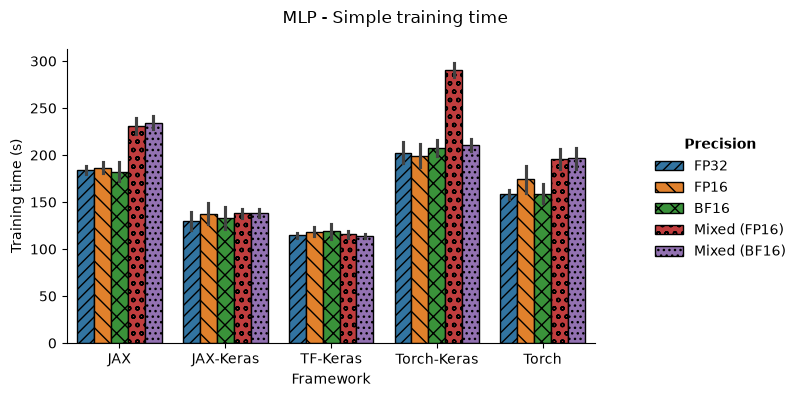

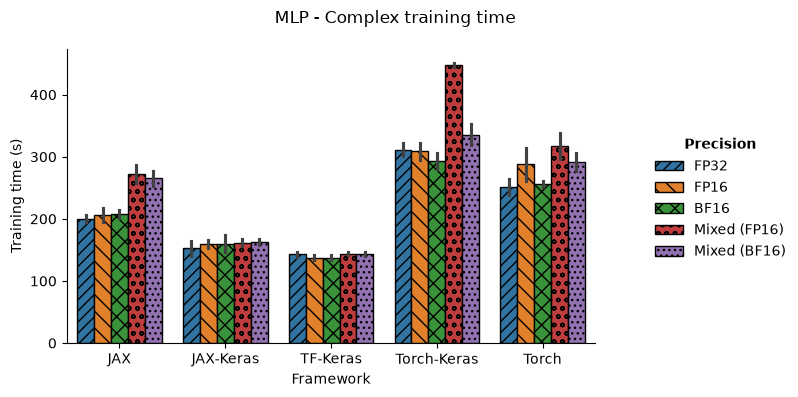

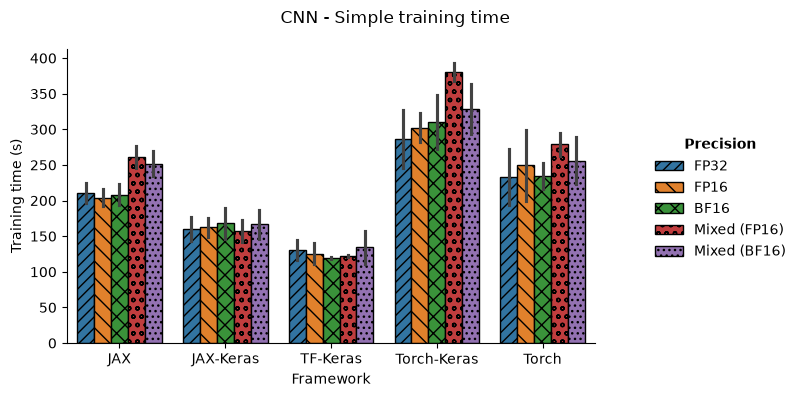

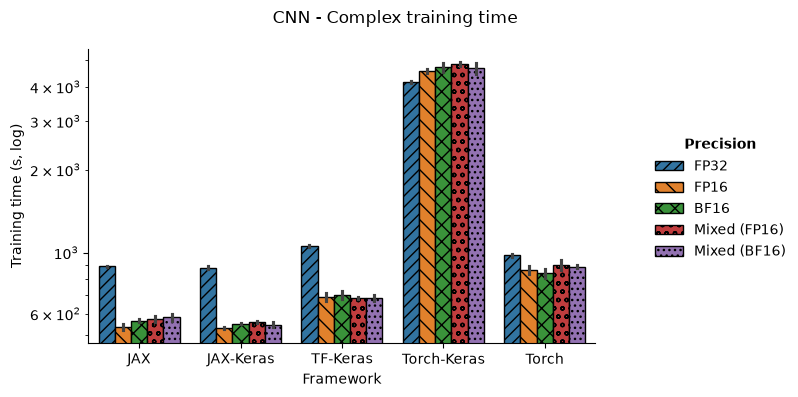

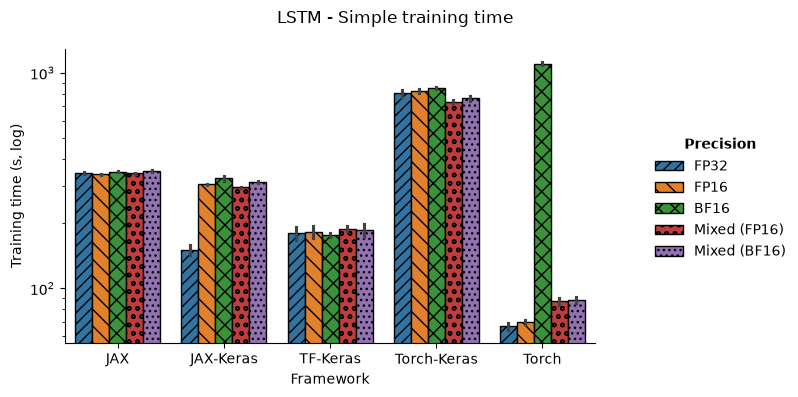

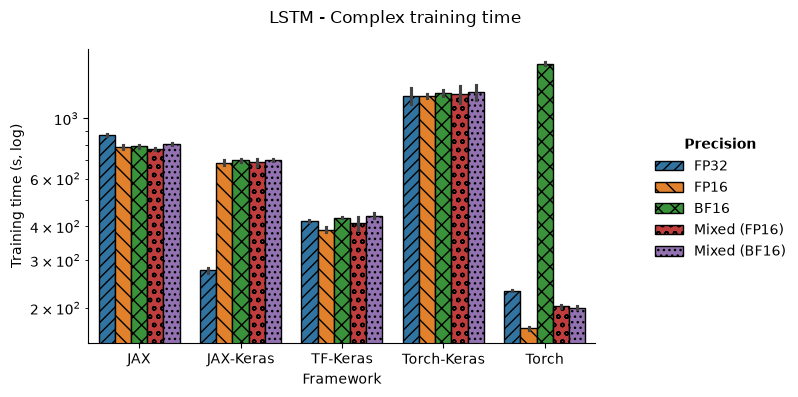

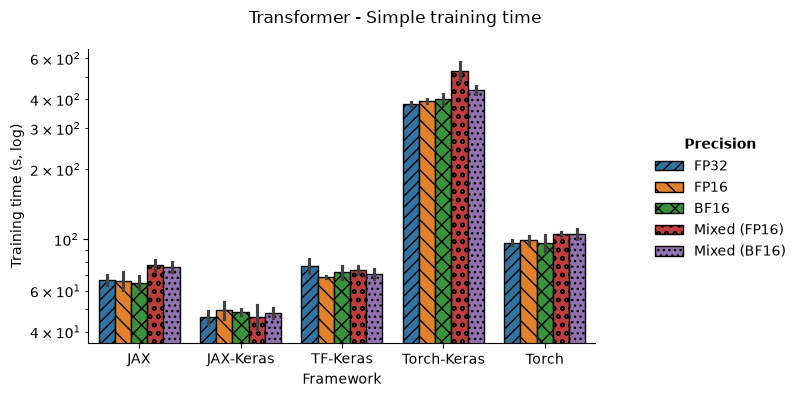

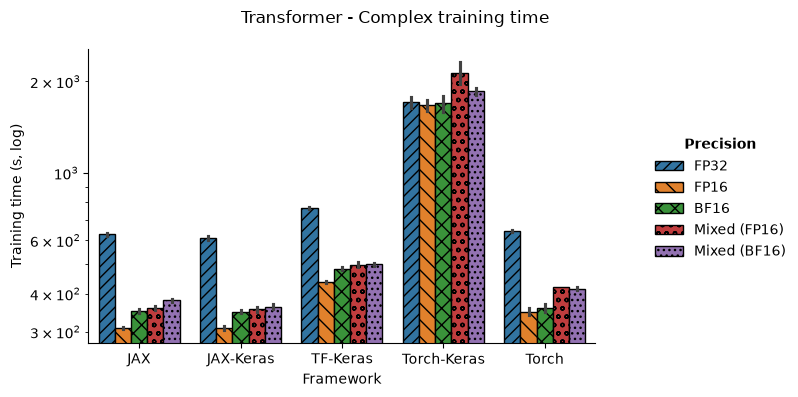

In [25]:
for model in orders["model_type"]:
    for complexity in orders["model_complexity"]:
        plot_training_time(metrics_df, model, complexity, log=model in regression_models or (model == "cnn" and complexity=="complex"))

In [26]:
compare_paired("training_time", "model_type=='transformer' and model_complexity=='complex'")

,training_time,pairs,diff_%,ci_low_%,ci_high_%,p,min_%,max_%
backend,,,,,,,,
jax-keras,385.080818,5,0.0,NaN,NaN,NaN,NaN,NaN
jax,392.420852,5,1.9,1.3,2.6,8.296668e-07,-0.2,5.3
torch,426.969547,5,10.9,10.0,11.8,1.808099e-17,3.0,18.5
tf-keras,526.923592,5,36.8,36.0,37.7,1.271982e-39,25.3,42.1
torch-keras,1803.486913,5,368.3,359.3,377.6,4.854685e-26,179.7,500.4


In [27]:
compare("training_time", "model_type=='cnn' and model_complexity=='complex' and backend=='tf-keras'", by="precision")

,training_time,diff_%,ci_low_%,ci_high_%,p
precision,,,,,
mixed_fp16,684.619814,0.0,NaN,NaN,NaN
mixed_bf16,684.986169,0.1,-2.3,2.5,9.573269e-01
fp16,689.712179,0.7,-2.8,4.3,6.086794e-01
bf16,701.890052,2.5,-0.7,5.7,9.715033e-02
fp32,1056.890644,54.4,52.8,55.9,7.086274e-12


In [28]:
# Fastest precision of each backend, against the fastest of Torch
compare("training_time", "model_type=='lstm' and model_complexity=='simple'", agg="min", ref="torch")

,training_time,diff_%
backend,,
torch,66.830880,0.0
jax-keras,150.513856,125.2
tf-keras,176.885484,164.7
jax,338.856229,407.0
torch-keras,731.916958,995.2


In [29]:
# BF16 on Torch distorts the mean on LSTM
compare("training_time", "model_type=='lstm' and model_complexity=='simple' and not (backend=='torch' and precision=='bf16')")

,training_time,diff_%
backend,,
torch,78.091904,0.0
tf-keras,182.934752,134.3
jax-keras,276.812789,254.5
jax,344.436798,341.1
torch-keras,794.083695,916.9


### Testing time

In [30]:
def plot_testing_time(df, model, complexity, log=False):
    plot_df = df.query("model_type==@model and model_complexity==@complexity")
    plot_df = add_labels(plot_df)

    plot = sns.catplot(
        data=plot_df,
        x="backend",
        y="testing_time",
        hue="precision",
        kind="bar",
        errorbar=t_ci,
        legend="auto"
    )
    
    add_patterns(plot)
    set_size(plot)

    model = labels["model_type"][model]
    complexity = labels["model_complexity"][complexity]

    # Title
    add_title(plot, f"{model} - {complexity} testing time", adjust=0.95)
    plot.set_titles("{col_name}")

    if log:
        plot.set(yscale="log")
        plot.set_axis_labels(titles["backend"], "Testing time (s, log)")
    else:
        plot.set_axis_labels(titles["backend"], "Testing time (s)")
        
    format_legend_title(plot)
    #sns.move_legend(plot, "upper left", bbox_to_anchor=(0.08, 0.89), frameon=True)
    plot.tight_layout()

    save_plot(plot, f"{model}/testing_time{model}_{complexity}")

    return plot

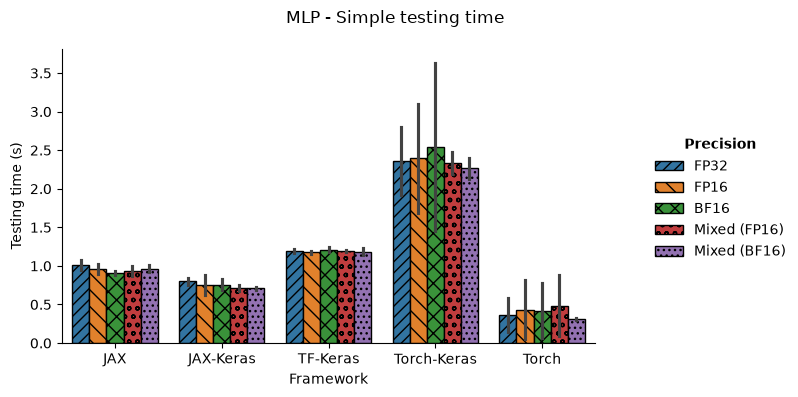

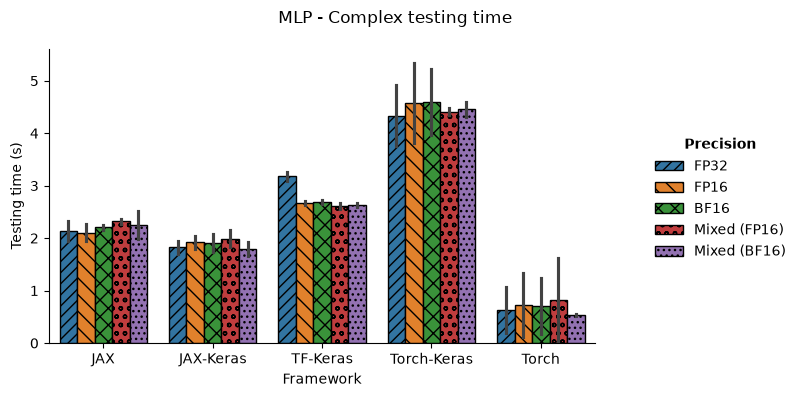

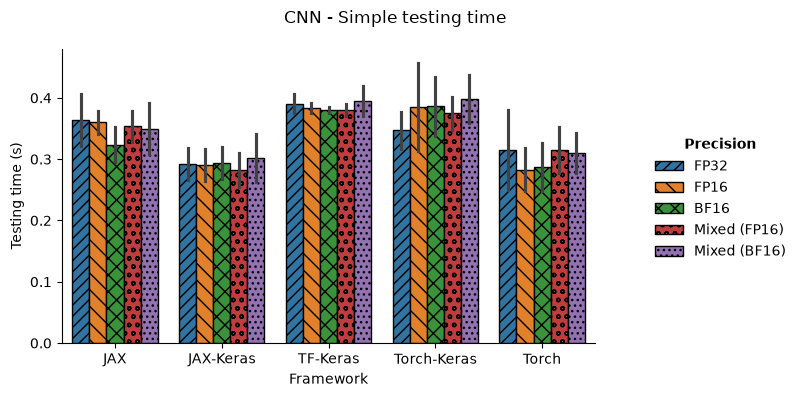

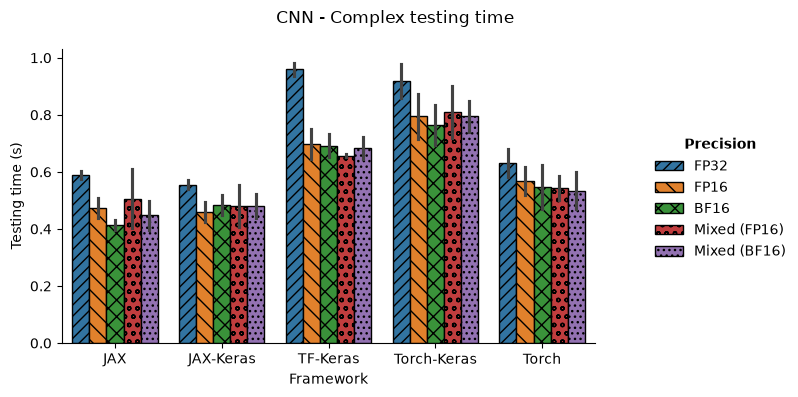

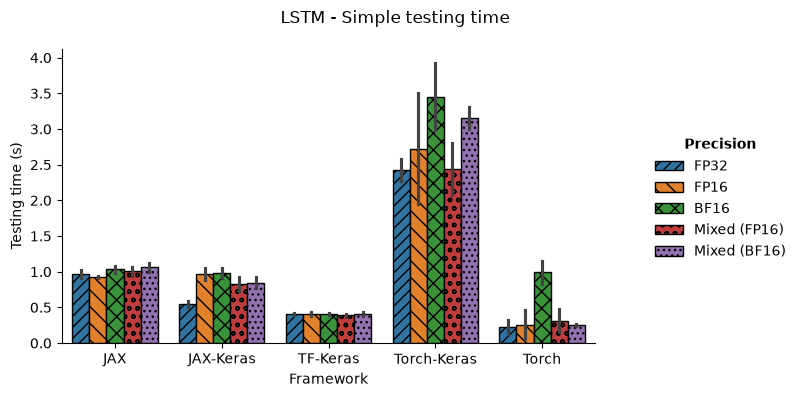

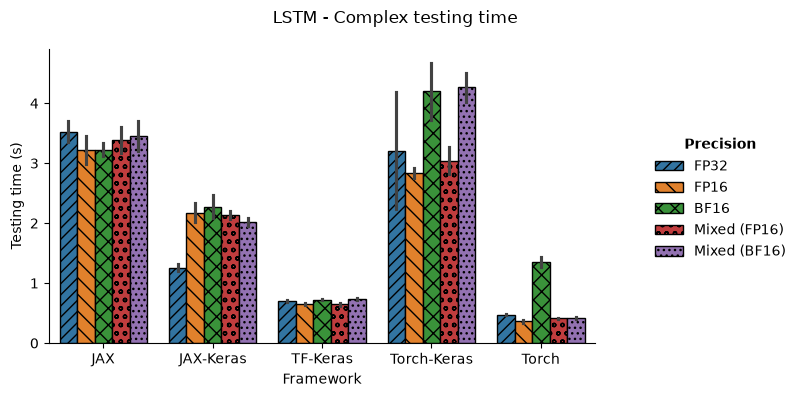

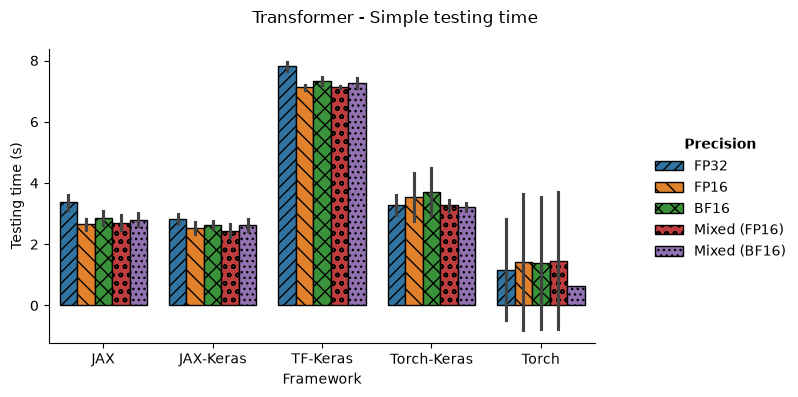

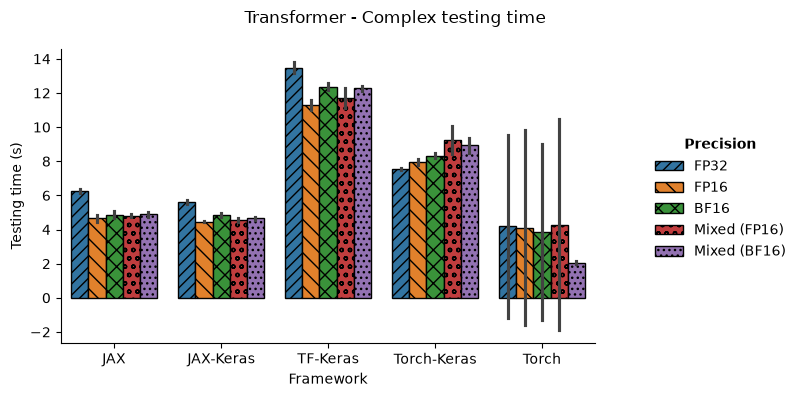

In [31]:
for model in orders["model_type"]:
    for complexity in orders["model_complexity"]:
        plot_testing_time(metrics_df, model, complexity)

In [32]:
compare_paired("testing_time", "model_type=='lstm' and model_complexity=='simple'")

,testing_time,pairs,diff_%,ci_low_%,ci_high_%,p,min_%,max_%
backend,,,,,,,,
torch,0.340049,5,0.0,NaN,NaN,NaN,NaN,NaN
tf-keras,0.403551,5,18.7,0.1,40.7,4.925271e-02,-59.1,83.7
jax-keras,0.817312,5,140.4,102.5,185.3,2.606648e-07,-1.1,273.3
jax,0.998639,5,193.7,147.6,248.3,4.709352e-08,4.0,338.3
torch-keras,2.812729,5,727.2,594.2,885.5,3.460599e-12,247.9,1139.9


In [33]:
compare("testing_time", "model_type=='lstm' and model_complexity=='complex' and backend=='jax'", by="precision", ref="max")

,testing_time,diff_%,ci_low_%,ci_high_%,p
precision,,,,,
fp16,3.216124,-8.8,-15.7,-1.8,0.019747
bf16,3.226886,-8.5,-13.6,-3.3,0.006168
mixed_fp16,3.381490,-4.1,-10.8,2.6,0.193731
mixed_bf16,3.450437,-2.1,-9.5,5.3,0.517644
fp32,3.525897,0.0,NaN,NaN,NaN


## GPU metrics

### GPU utilisation

In [34]:
def plot_utilisation_heatmap(df, model, complexity):
    plot_df = df.query("model_type==@model and model_complexity==@complexity")
    plot_df = plot_df.groupby(experiment_config[:-1])["train_gpu_utilization_mean"].mean().reset_index()
    plot_df = add_labels(plot_df)

    plot_df = plot_df.pivot_table(
        index="precision", columns="backend", values="train_gpu_utilization_mean"
    )

    plot = sns.heatmap(
        plot_df,
        annot=True,
        fmt=".1f",
        cmap="YlGnBu",
        cbar_kws={"label": "GPU usage (%)"}
    )
    
    model = labels["model_type"][model]
    complexity = labels["model_complexity"][complexity]

    add_title(plot, f"{model} - {complexity} mean GPU usage", adjust=0.92)
    plot.set_xlabel(titles["backend"])
    plot.set_ylabel(titles["precision"])

    save_plot(plot, f"{model}/usage_heatmap_{model}_{complexity}")

    return plot

/tmp/ipykernel_2273336/874083804.py:3: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plot.figure.subplots_adjust(top=adjust)
/tmp/ipykernel_2273336/874083804.py:3: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plot.figure.subplots_adjust(top=adjust)
/tmp/ipykernel_2273336/874083804.py:3: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plot.figure.subplots_adjust(top=adjust)
/tmp/ipykernel_2273336/874083804.py:3: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plot.figure.subplots_adjust(top=adjust)
/tmp/ipykernel_2273336/874083804.py:3: UserWarning: This figure was using a layout engine that is incomp

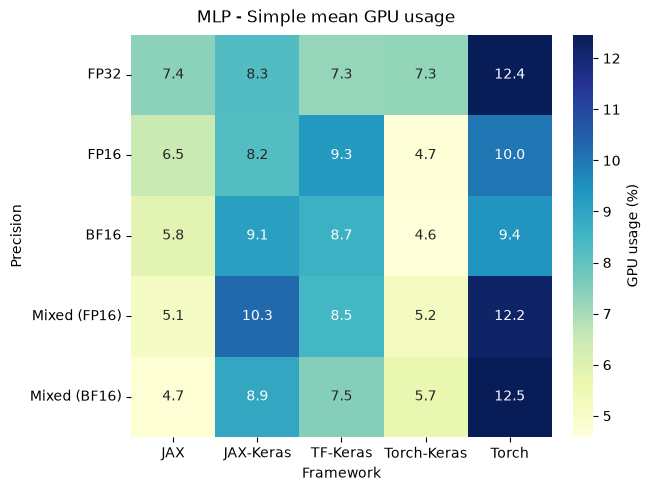

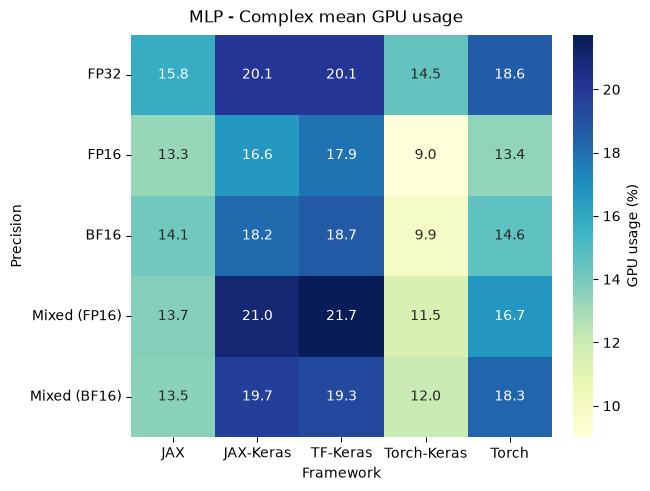

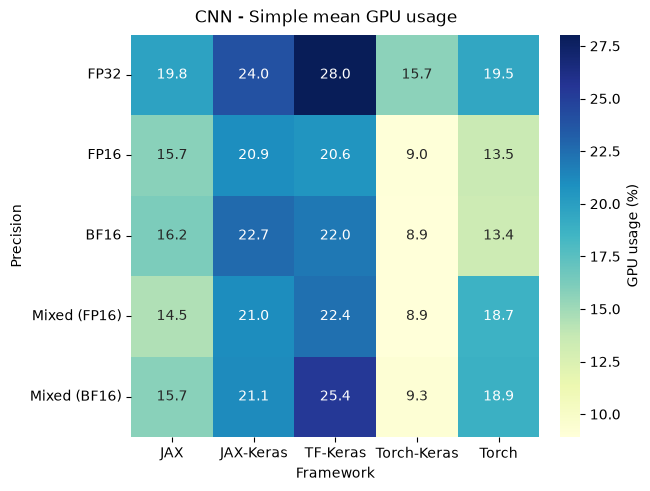

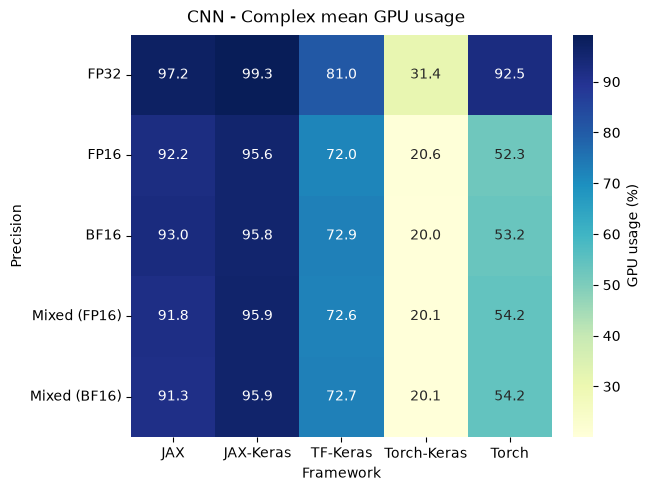

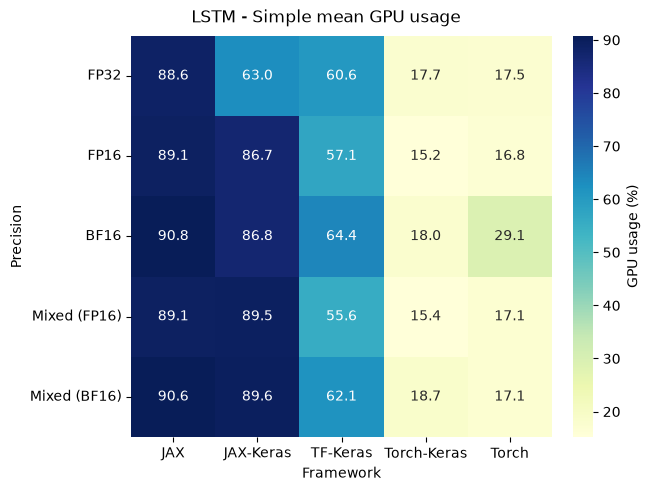

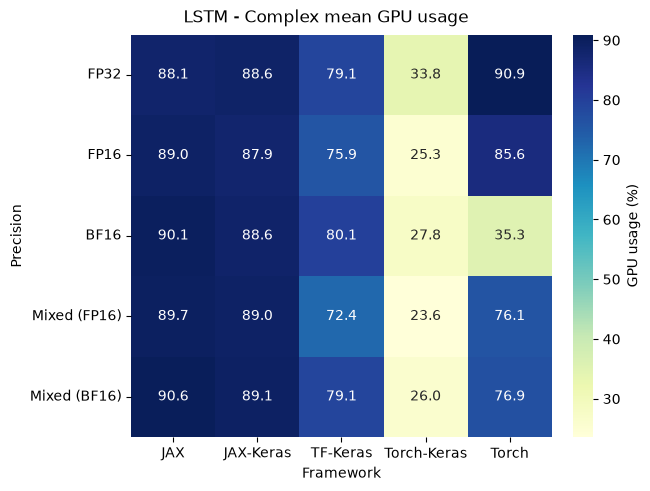

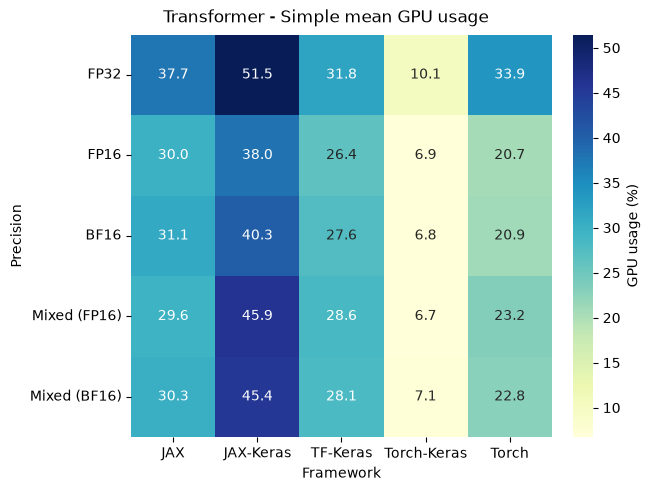

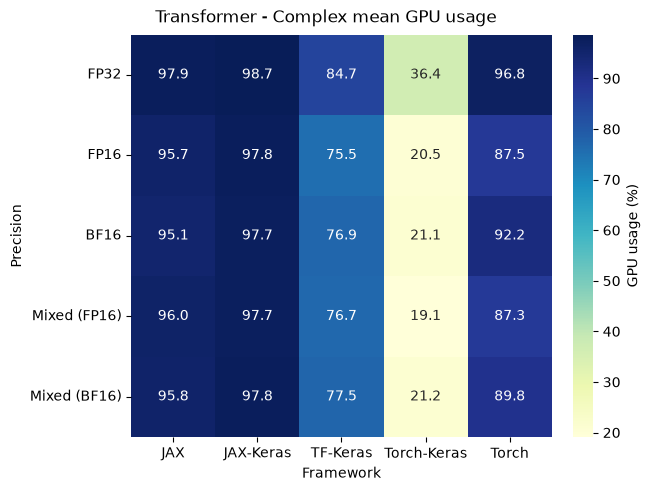

In [35]:
for model in orders["model_type"]:
    for complexity in orders["model_complexity"]:
        plt.figure(constrained_layout=True)
        plot = plot_utilisation_heatmap(metrics_df, model, complexity)

In [36]:
compare_paired("train_gpu_utilization_mean", "model_type=='transformer' and model_complexity=='complex'", ref="max")

,train_gpu_utilization_mean,pairs,diff_%,ci_low_%,ci_high_%,p,min_%,max_%
backend,,,,,,,,
torch-keras,22.960934,5,-76.6,-77.0,-76.1,4.077409e-22,-80.4,-63.1
tf-keras,78.179827,5,-20.2,-20.5,-19.9,2.823103e-23,-22.8,-14.2
torch,90.665836,5,-7.4,-8.2,-6.6,1.076523e-09,-10.7,-1.9
jax,96.084152,5,-1.9,-2.2,-1.5,3.698621e-09,-2.6,-0.8
jax-keras,97.930798,5,0.0,NaN,NaN,NaN,NaN,NaN


In [37]:
# BF16 on Torch distorts the mean on LSTM
compare("train_gpu_utilization_mean", "model_type=='lstm' and model_complexity=='simple' and not (backend=='torch' and precision=='bf16')", ref="max")

,train_gpu_utilization_mean,diff_%
backend,,
torch-keras,17.018785,-81.0
torch,17.149602,-80.9
tf-keras,59.944345,-33.1
jax-keras,83.126649,-7.3
jax,89.657082,0.0


### GPU memory

In [38]:
# Highest peak over all the runs of each backend (compare would average the seeds first)
memory_df = metrics_df.groupby("backend")["train_gpu_memory_max"].max().sort_values(ascending=False).to_frame()
memory_df["diff_%"] = ((memory_df["train_gpu_memory_max"] / memory_df["train_gpu_memory_max"].max() - 1) * 100).round(1)
memory_df

,train_gpu_memory_max,diff_%
backend,,
tf-keras,78.573425,0.0
jax-keras,60.717957,-22.7
jax,60.694519,-22.8
torch-keras,5.657410,-92.8
torch,4.186707,-94.7


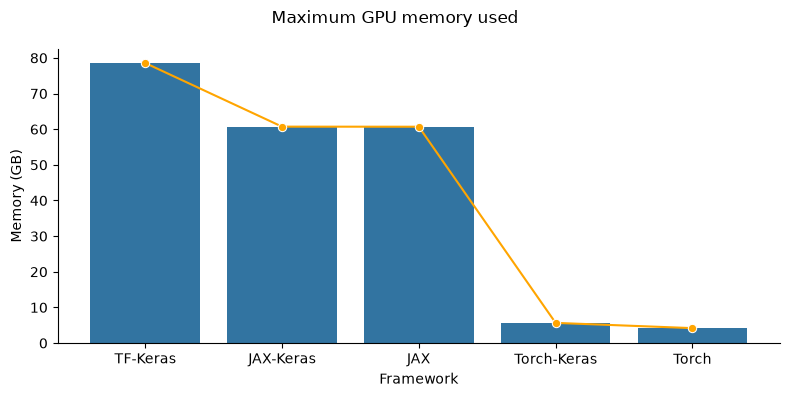

In [39]:
base_df = add_labels(memory_df.reset_index())

plot = sns.catplot(
    data=base_df,
    x="backend",
    y="train_gpu_memory_max",
    kind="bar",
    errorbar="sd",
    order=base_df["backend"]
)

sns.lineplot(
    x=base_df["backend"],
    y=base_df["train_gpu_memory_max"],
    ax=plot.ax,
    marker="o",
    color="orange"
)

set_size(plot)

add_title(plot, "Maximum GPU memory used")
plot.set_axis_labels(titles["backend"], "Memory (GB)")

plt.tight_layout()

save_plot(plot, "memory_bars")

## Energy consumption

CodeCarbon measures each phase as a sequence of tasks (training and validation of every epoch, and test). GPU energy comes from the NVML energy counter of the GPU used; CPU energy from RAPL, or estimated from load × TDP when RAPL is not readable; and RAM energy is always estimated. Training energy includes validation, as `training_time` does.

### GPU energy: GPU monitor vs. CodeCarbon

The GPU monitor samples the GPU power every second, and integrating it gives the GPU energy of the training. Both measures agree within a few percent in all runs but one, so the rest of the analysis uses only the CodeCarbon energy.

In [40]:
gpu_check_df = metrics_df[experiment_config + ["train_nvml_gpu_energy", "train_cc_gpu_energy"]].copy()
gpu_check_df["ratio"] = gpu_check_df["train_nvml_gpu_energy"] / gpu_check_df["train_cc_gpu_energy"]
gpu_check_df["gap"] = (gpu_check_df["ratio"] - 1).abs()

print(f"Median ratio: {gpu_check_df['ratio'].median():.4f}")
for threshold in [0.01, 0.02, 0.05]:
    print(f"Runs within {threshold:.0%}: {(gpu_check_df['gap'] < threshold).mean():.1%}")

gpu_check_df.groupby(["model_type", "backend"])["ratio"].describe()

Median ratio: 1.0062
Runs within 1%: 73.8%
Runs within 2%: 96.3%
Runs within 5%: 99.8%


count      mean       std       min       25%  \
model_type  backend                                                      
cnn         jax           50.0  1.004348  0.005719  0.993155  1.000208   
            jax-keras     50.0  1.005537  0.004674  0.999071  1.001189   
            tf-keras      50.0  1.006170  0.006880  0.994100  1.000872   
            torch         50.0  1.004436  0.003438  0.998989  1.001338   
            torch-keras   50.0  1.006310  0.003535  0.999474  1.003206   
lstm        jax           50.0  1.002142  0.001628  0.995650  1.001122   
            jax-keras     50.0  1.003106  0.003118  0.995209  1.001354   
            tf-keras      50.0  1.004194  0.003401  0.996475  1.002209   
            torch         50.0  1.009635  0.008700  0.998946  1.003283   
            torch-keras   50.0  1.003462  0.002870  0.993481  1.001632   
mlp         jax           50.0  1.007952  0.003001  1.000620  1.006324   
            jax-keras     50.0  1.010671  0.003578  1.003100  1.008215   
            tf-keras      50.0  1.011444  0.004967  0.999176  1.008890   
            torch         50.0  1.007771  0.003214  1.000839  1.005619   
            torch-keras   50.0  1.009967  0.002675  1.004373  1.008334   
transformer jax           50.0  1.005668  0.012369  0.971004  0.999654   
            jax-keras     50.0  1.011305  0.017825  0.960785  1.002750   
            tf-keras      50.0  1.006742  0.013047  0.983554  0.996678   
            torch         50.0  1.007188  0.007556  0.993636  1.001220   
            torch-keras   50.0  1.003964  0.005562  0.984887  1.001296   

                              50%       75%       max  
model_type  backend                                    
cnn         jax          1.004659  1.008445  1.018801  
            jax-keras    1.003983  1.009275  1.014327  
            tf-keras     1.004560  1.010938  1.023718  
            torch        1.004613  1.006980  1.011390  
            torch-keras  1.006701  1.008868  1.012530  
lstm        jax          1.002482  1.003144  1.005327  
            jax-keras    1.002661  1.004935  1.011392  
            tf-keras     1.004329  1.006654  1.011687  
            torch        1.009692  1.013323  1.054900  
            torch-keras  1.004439  1.005240  1.007706  
mlp         jax          1.008225  1.010068  1.015720  
            jax-keras    1.010334  1.013149  1.019004  
            tf-keras     1.012225  1.014595  1.021298  
            torch        1.007194  1.009213  1.017865  
            torch-keras  1.009581  1.011915  1.016227  
transformer jax          1.003664  1.011555  1.038431  
            jax-keras    1.008067  1.016236  1.076304  
            tf-keras     1.007382  1.016668  1.036285  
            torch        1.006222  1.011832  1.032195  
            torch-keras  1.005959  1.007889  1.010409

In [41]:
gpu_check_df.sort_values("gap", ascending=False).head()

,backend,model_type,model_complexity,precision,seed,train_nvml_gpu_energy,train_cc_gpu_energy,ratio,gap
383,jax-keras,transformer,simple,fp16,45,5.060562,4.701797,1.076304,0.076304
688,torch,lstm,simple,fp32,45,4.779961,4.531198,1.054900,0.054900
398,jax-keras,transformer,simple,mixed_fp16,45,4.887531,4.689608,1.042205,0.042205
387,jax-keras,transformer,simple,fp32,44,6.046923,6.293732,0.960785,0.039215
188,jax,transformer,simple,fp32,45,7.650034,7.366917,1.038431,0.038431


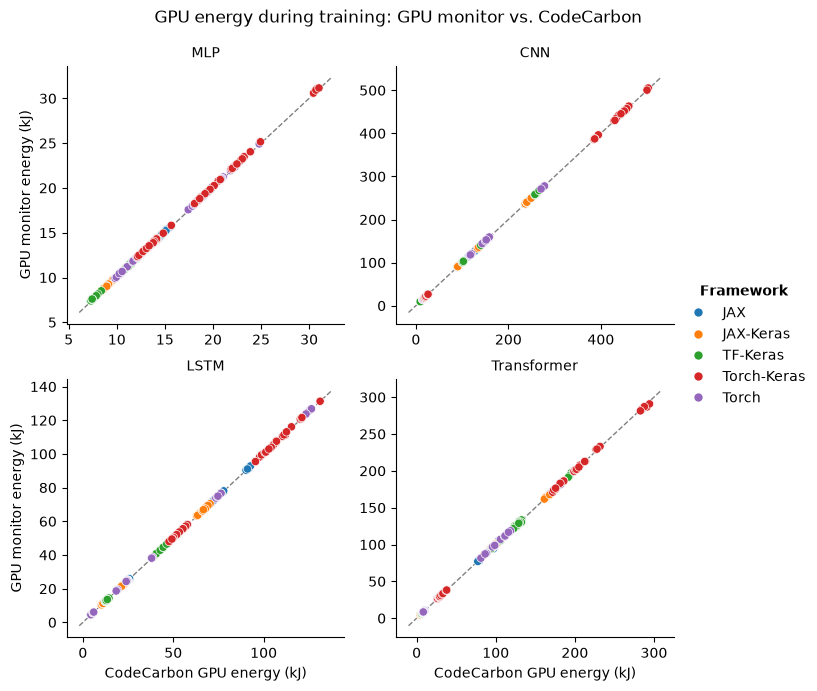

In [42]:
plot = sns.relplot(
    data=add_labels(gpu_check_df),
    x="train_cc_gpu_energy",
    y="train_nvml_gpu_energy",
    hue="backend",
    col="model_type",
    col_wrap=2,
    height=3.5,
    facet_kws={"sharex": False, "sharey": False}
)

for ax in plot.axes.flat:
    lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
    ax.plot(lims, lims, color="grey", linestyle="--", linewidth=1, zorder=-1)

plot.set_titles(col_template="{col_name}")
plot.set_axis_labels("CodeCarbon GPU energy (kJ)", "GPU monitor energy (kJ)")
format_legend_title(plot, "backend")
add_title(plot, "GPU energy during training: GPU monitor vs. CodeCarbon", adjust=0.9)

save_plot(plot, "gpu_energy_nvml_vs_codecarbon")

### Total energy

In [43]:
def plot_total_energy(df, model, complexity, log=False):
    plot_df = df.query("model_type==@model and model_complexity==@complexity")
    plot_df = add_labels(plot_df)

    plot = sns.catplot(
        data=plot_df,
        x="backend",
        y="train_cc_energy",
        hue="precision",
        kind="bar",
        errorbar=t_ci,
        legend="auto"
    )

    add_patterns(plot)
    set_size(plot)

    model = labels["model_type"][model]
    complexity = labels["model_complexity"][complexity]

    add_title(plot, f"{model} - {complexity} total energy consumption during training (CodeCarbon)")
    format_legend_title(plot)

    if log:
        plot.set(yscale="log")
        plot.set_axis_labels(titles["backend"], "Energy (kJ, log)")
    else:
        plot.set_axis_labels(titles["backend"], "Energy (kJ)")

    save_plot(plot, f"{model}/cc_energy_bars_{model}_{complexity}")

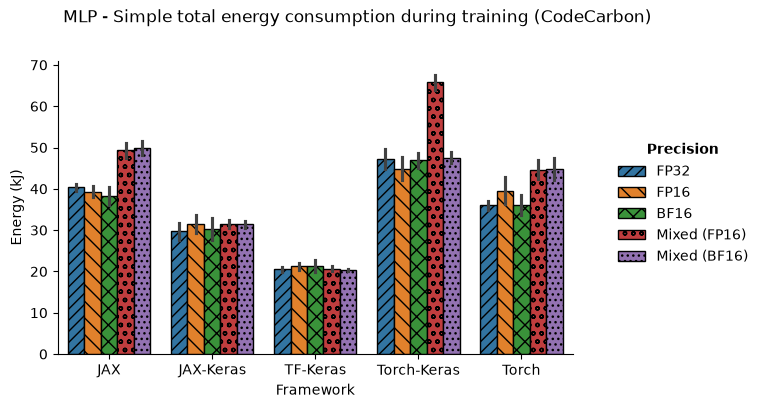

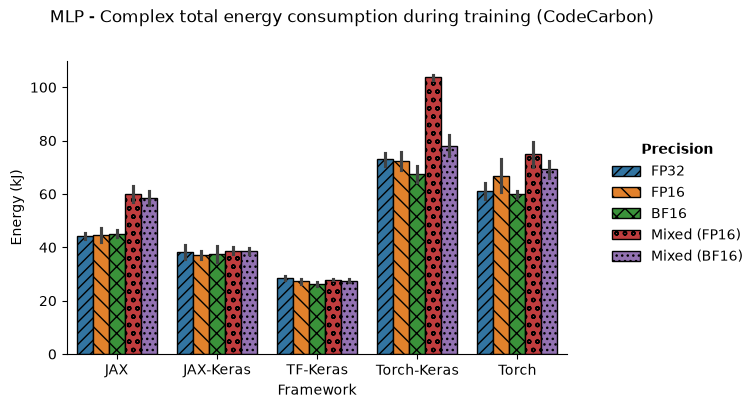

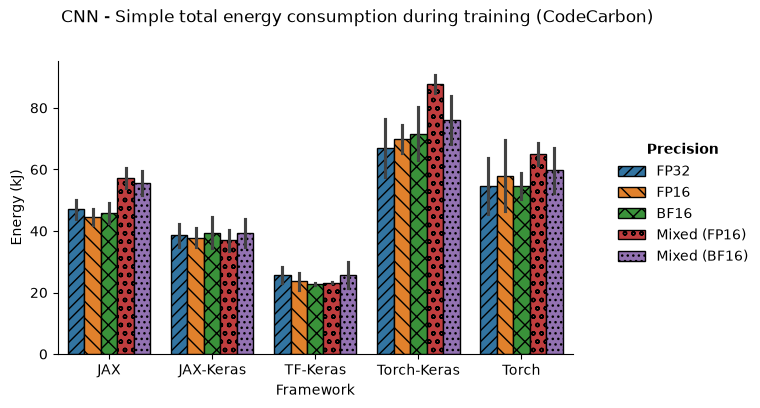

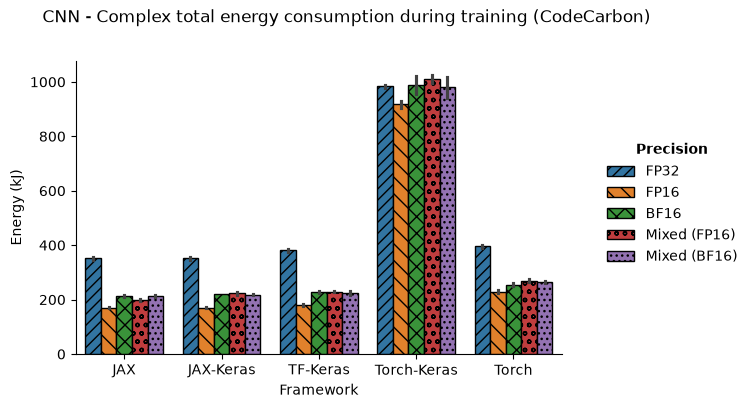

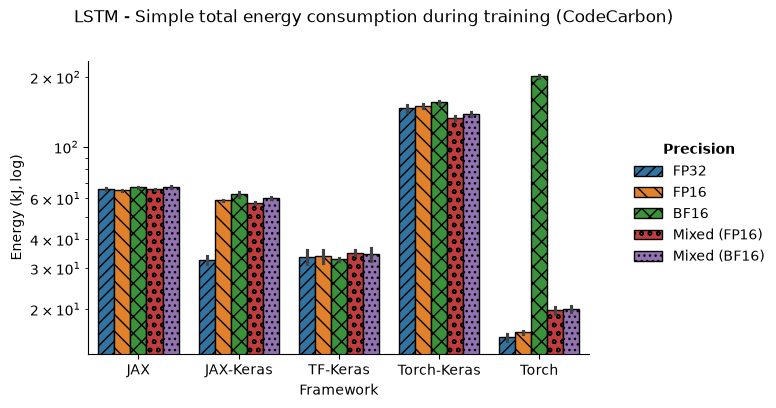

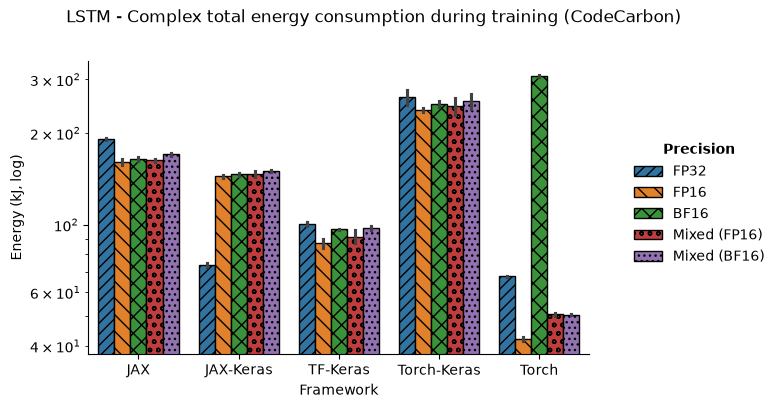

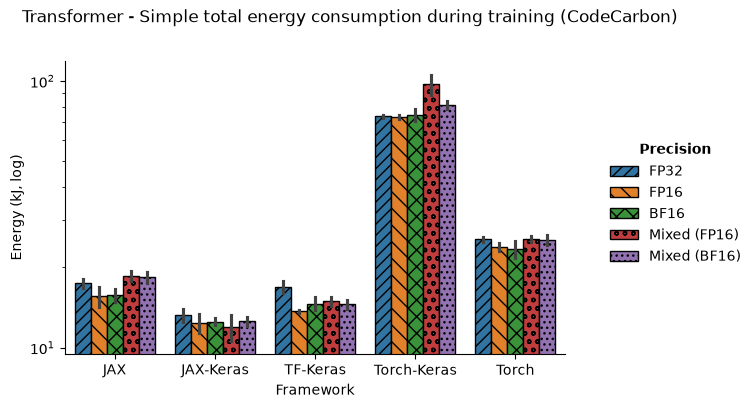

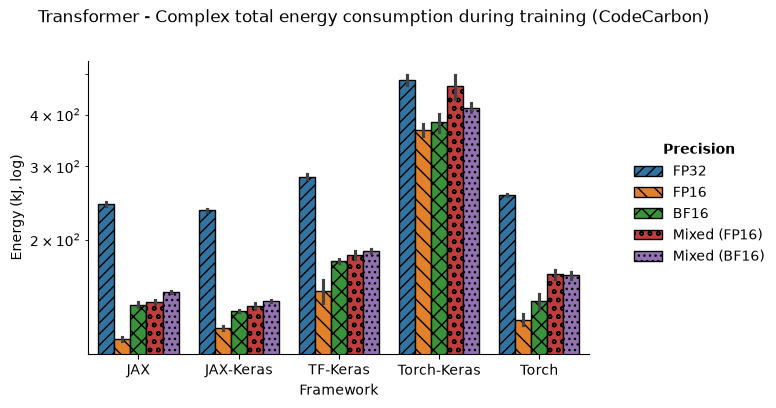

In [44]:
for model in orders["model_type"]:
    for complexity in orders["model_complexity"]:
        plot_total_energy(metrics_df, model, complexity, log=model in regression_models)

In [45]:
compare_paired("train_cc_energy", "model_type=='lstm' and model_complexity=='simple'")

,train_cc_energy,pairs,diff_%,ci_low_%,ci_high_%,p,min_%,max_%
backend,,,,,,,,
torch,28.626944,5,0.0,NaN,NaN,NaN,NaN,NaN
tf-keras,33.910403,5,18.5,16.1,20.9,6.766407e-14,-83.7,121.7
jax-keras,52.915438,5,84.8,82.7,87.0,1.719793e-33,-69.0,271.3
jax,66.242895,5,131.4,129.2,133.6,1.277825e-30,-66.8,337.7
torch-keras,144.700111,5,405.5,399.5,411.6,6.825786e-50,-23.0,871.4


In [46]:
# Each precision against FP32, within each backend
compare("train_cc_energy", "model_type=='lstm' and model_complexity=='simple'", by=["backend", "precision"], within="backend", ref="fp32")

train_cc_energy  diff_%  ci_low_%  ci_high_%  \
backend     precision                                                  
jax         fp16              65.141007    -1.5      -2.5       -0.6   
            mixed_fp16        65.595862    -0.9      -1.8        0.1   
            fp32              66.159451     0.0       NaN        NaN   
            bf16              66.929186     1.2       0.2        2.1   
            mixed_bf16        67.415254     1.9       0.7        3.1   
jax-keras   fp32              32.583305     0.0       NaN        NaN   
            mixed_fp16        57.397513    76.2      72.4       79.9   
            fp16              58.898586    80.8      77.0       84.6   
            mixed_bf16        60.276498    85.0      81.2       88.8   
            bf16              62.484298    91.8      86.6       96.9   
tf-keras    bf16              32.805379    -2.1      -8.9        4.7   
            fp32              33.514892     0.0       NaN        NaN   
            fp16              33.778228     0.8      -7.1        8.7   
            mixed_bf16        34.513799     3.0      -5.0       10.9   
            mixed_fp16        34.982611     4.4      -2.4       11.1   
torch       fp32              15.114550     0.0       NaN        NaN   
            fp16              15.860847     4.9       1.6        8.2   
            mixed_fp16        19.783367    30.9      26.1       35.7   
            mixed_bf16        20.080730    32.9      28.6       37.1   
            bf16             201.870855  1235.6    1214.2     1257.0   
torch-keras mixed_fp16       133.737490    -8.9     -12.6       -5.2   
            mixed_bf16       138.668853    -5.6      -9.3       -1.8   
            fp32             146.823366     0.0       NaN        NaN   
            fp16             149.879974     2.1      -1.7        5.8   
            bf16             155.443817     5.9       2.2        9.5   

                                   p  
backend     precision                 
jax         fp16        6.944523e-03  
            mixed_fp16  6.506953e-02  
            fp32                 NaN  
            bf16        2.457461e-02  
            mixed_bf16  5.483120e-03  
jax-keras   fp32                 NaN  
            mixed_fp16  7.791100e-08  
            fp16        9.078699e-08  
            mixed_bf16  3.726083e-09  
            bf16        2.828358e-10  
tf-keras    bf16        4.477853e-01  
            fp32                 NaN  
            fp16        8.242276e-01  
            mixed_bf16  4.115541e-01  
            mixed_fp16  1.571738e-01  
torch       fp32                 NaN  
            fp16        1.022784e-02  
            mixed_fp16  9.691336e-07  
            mixed_bf16  1.393072e-07  
            bf16        4.603501e-09  
torch-keras mixed_fp16  1.148061e-03  
            mixed_bf16  1.037290e-02  
            fp32                 NaN  
            fp16        2.248718e-01  
            bf16        9.507183e-03

### Energy by component

In [47]:
energy_components = {
    "train_cc_gpu_energy": "GPU",
    "train_cc_cpu_energy": "CPU",
    "train_cc_ram_energy": "RAM",
}

# Share of each component in the training energy, over precisions and seeds
components_df = (
    metrics_df
    .groupby(["model_type", "model_complexity", "backend"])[list(energy_components)]
    .sum()
)
components_df = components_df.div(components_df.sum(axis=1), axis=0).rename(columns=energy_components)
components_df.round(3)

GPU    CPU    RAM
model_type  model_complexity backend                         
cnn         complex          jax          0.622  0.187  0.191
                             jax-keras    0.634  0.185  0.181
                             tf-keras     0.647  0.138  0.214
                             torch        0.601  0.178  0.221
                             torch-keras  0.455  0.216  0.329
            simple           jax          0.320  0.364  0.316
                             jax-keras    0.310  0.396  0.294
                             tf-keras     0.404  0.235  0.361
                             torch        0.299  0.402  0.298
                             torch-keras  0.297  0.403  0.300
lstm        complex          jax          0.454  0.216  0.331
                             jax-keras    0.462  0.216  0.322
                             tf-keras     0.494  0.198  0.308
                             torch        0.444  0.234  0.322
                             torch-keras  0.434  0.223  0.343
            simple           jax          0.380  0.258  0.362
                             jax-keras    0.370  0.275  0.355
                             tf-keras     0.383  0.242  0.374
                             torch        0.350  0.289  0.361
                             torch-keras  0.365  0.253  0.382
mlp         complex          jax          0.325  0.358  0.318
                             jax-keras    0.319  0.391  0.291
                             tf-keras     0.413  0.231  0.356
                             torch        0.307  0.398  0.295
                             torch-keras  0.300  0.402  0.299
            simple           jax          0.312  0.362  0.326
                             jax-keras    0.287  0.409  0.304
                             tf-keras     0.363  0.251  0.386
                             torch        0.285  0.410  0.305
                             torch-keras  0.288  0.407  0.305
transformer complex          jax          0.699  0.122  0.179
                             jax-keras    0.699  0.122  0.179
                             tf-keras     0.686  0.123  0.191
                             torch        0.697  0.125  0.178
                             torch-keras  0.509  0.193  0.299
            simple           jax          0.376  0.343  0.281
                             jax-keras    0.409  0.331  0.259
                             tf-keras     0.450  0.218  0.333
                             torch        0.346  0.373  0.280
                             torch-keras  0.370  0.258  0.372

In [48]:
def plot_energy_components(df, model):
    patterns = ['///', 'xx', '...']
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

    for ax, complexity in zip(axes, orders["model_complexity"]):
        plot_df = df.loc[(model, complexity)].reindex(orders["backend"])
        bottoms = np.zeros(len(plot_df))

        for (component, values), pattern in zip(plot_df.items(), patterns):
            ax.bar(
                [labels["backend"][b] for b in plot_df.index],
                values,
                bottom=bottoms,
                label=component,
                hatch=pattern,
                edgecolor="black",
                linewidth=0.5
            )
            bottoms += values.values

        ax.set_title(labels["model_complexity"][complexity])
        ax.set_xlabel(titles["backend"])
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.tick_params(axis="x", rotation=45)

    axes[0].set_ylabel("Share of training energy")

    handles, leg_labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, leg_labels, title=r"$\bf{Component}$", loc="center right")

    model = labels["model_type"][model]
    fig.suptitle(f"{model} - training energy by component (CodeCarbon)")
    fig.tight_layout(rect=(0, 0, 0.88, 1))

    save_plot(fig, f"{model}/cc_energy_components_{model}")

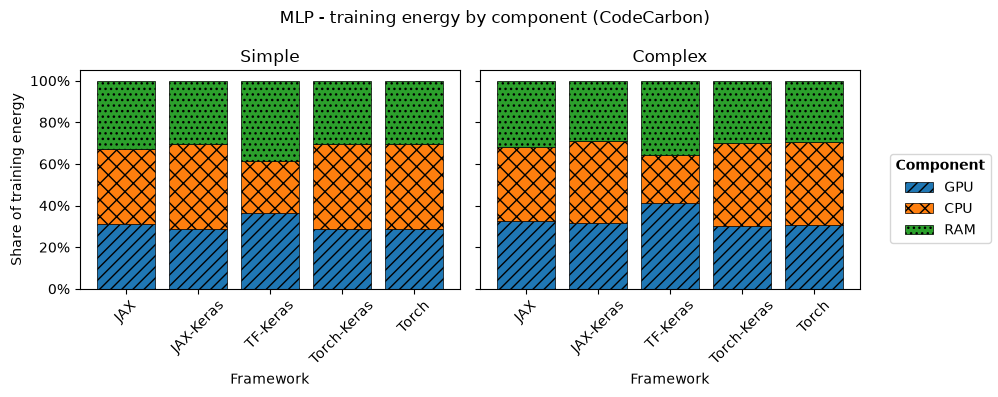

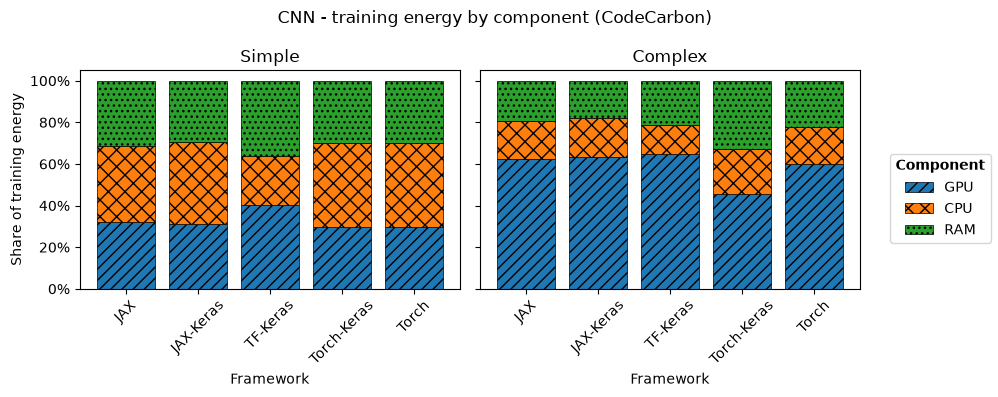

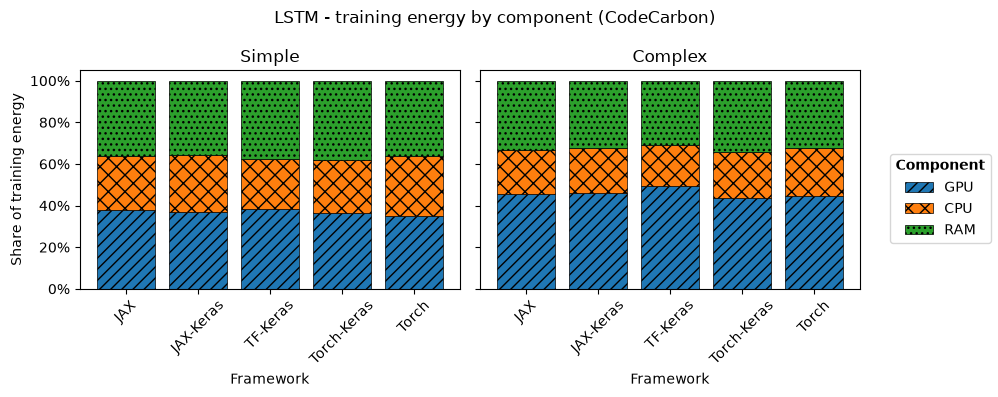

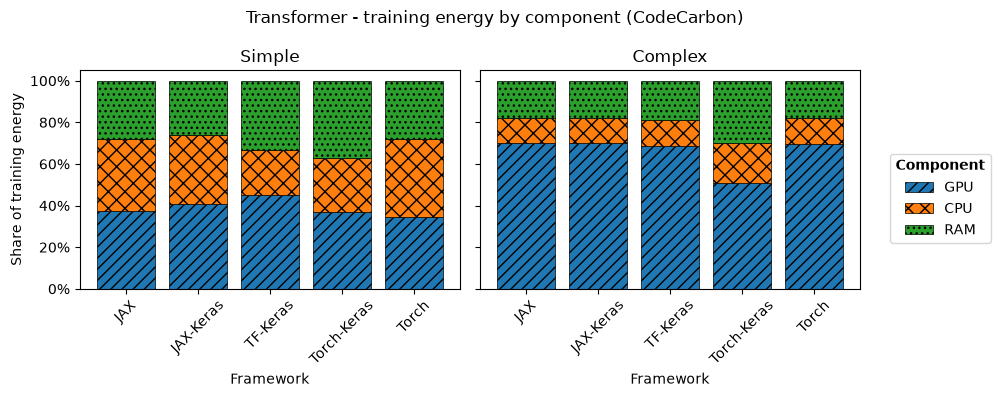

In [49]:
for model in orders["model_type"]:
    plot_energy_components(components_df, model)

## Test results

### Experiment status

In [50]:
df_list = []

for keys, subset_df in index_df[index_df["filename"] == "test"].groupby(experiment_config):
    backend, model, model_complexity, precision, seed = keys

    base_df = pd.read_csv(subset_df.iloc[0]["path"])

    base_df["backend"] = backend
    base_df["model_type"] = model
    base_df["model_complexity"] = model_complexity
    base_df["precision"] = precision
    base_df["seed"] = seed

    df_list.append(base_df)

test_df = pd.concat(df_list, ignore_index=True)
test_df = exp_config_category(test_df)

test_df = test_df[experiment_config + ["time", "loss", "metric"]]
test_df = test_df.sort_values(by=experiment_config).reset_index(drop=True)

test_df.head()

,backend,model_type,model_complexity,precision,seed,time,loss,metric
0,jax,mlp,simple,fp32,42,0.986020,0.284254,0.8963
1,jax,mlp,simple,fp32,43,0.960442,0.284276,0.8986
2,jax,mlp,simple,fp32,44,1.044659,0.280287,0.9009
3,jax,mlp,simple,fp32,45,1.092712,0.279591,0.8992
4,jax,mlp,simple,fp32,46,0.975741,0.283216,0.8980


In [51]:
failed_df: pd.DataFrame = (
    test_df.groupby(experiment_config, observed=True)
    .apply(lambda g: g[["loss", "metric"]].isna().values.any())
    .reset_index(name="failed")
)

# A run whose validation loss never improves on the first epoch did not train, even without NaN
best_epoch_df = exp_config_category(metrics_df[experiment_config + ["best_epoch"]].copy())
failed_df = failed_df.merge(best_epoch_df, on=experiment_config, how="left")
failed_df["not_trained"] = ~failed_df["failed"] & (failed_df["best_epoch"] == 0)

# Add experiments with errors
error_df["error"] = True

failed_df = failed_df.merge(
    error_df[experiment_config + ["error"]],
    on=experiment_config,
    how="outer"
)

for status in ["failed", "not_trained", "error"]:
    failed_df[status] = failed_df[status].fillna(False).astype(bool)

failed_df["success"] = ~(failed_df["failed"] | failed_df["not_trained"] | failed_df["error"])

failed_df.head()

,backend,model_type,model_complexity,precision,seed,failed,best_epoch,not_trained,error,success
0,jax,cnn,complex,bf16,42,False,7.0,False,False,True
1,jax,cnn,complex,bf16,43,False,7.0,False,False,True
2,jax,cnn,complex,bf16,44,False,70.0,False,False,True
3,jax,cnn,complex,bf16,45,False,7.0,False,False,True
4,jax,cnn,complex,bf16,46,False,9.0,False,False,True


In [52]:
assert not failed_df["error"].any(), "The status figure has no category for runs that ended in error"

# A configuration takes the worst status of its seeds; the figure annotates the ones that only partly succeed
status_df = (
    failed_df.groupby(experiment_config[:-1], observed=True)
    .agg(
        n_seeds=("seed", "count"),
        n_success=("success", "sum"),
        any_failed=("failed", "any"),
        any_not_trained=("not_trained", "any"),
    )
    .reset_index()
)
status_df["status"] = np.select(
    [status_df["any_failed"], status_df["any_not_trained"]],
    ["failed", "not_trained"],
    default="success",
)

status_df.head()

,backend,model_type,model_complexity,precision,n_seeds,n_success,any_failed,any_not_trained,status
0,jax,mlp,simple,fp32,5,5,False,False,success
1,jax,mlp,simple,fp16,5,0,True,False,failed
2,jax,mlp,simple,bf16,5,5,False,False,success
3,jax,mlp,simple,mixed_fp16,5,5,False,False,success
4,jax,mlp,simple,mixed_bf16,5,5,False,False,success


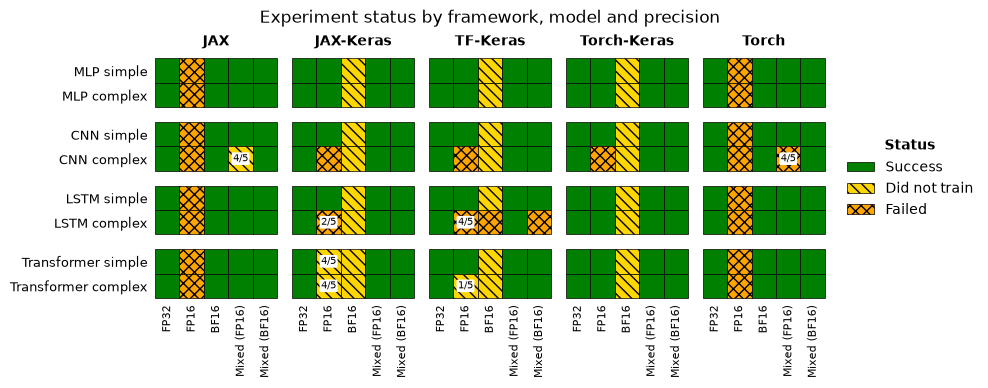

In [53]:
status_styles = {
    "success":     {"label": "Success",       "color": "green",  "hatch": ""},
    "not_trained": {"label": "Did not train", "color": "gold",   "hatch": "\\\\\\"},
    "failed":      {"label": "Failed",        "color": "orange", "hatch": "xxx"},
}
group_gap = 0.6  # Blank space between frameworks (columns) and between models (rows)

rows = [(m, c) for m in orders["model_type"] for c in orders["model_complexity"]]
cols = [(b, p) for b in orders["backend"] for p in orders["precision"]]
row_y = {r: i + (i // len(orders["model_complexity"])) * group_gap for i, r in enumerate(rows)}
col_x = {c: i + (i // len(orders["precision"])) * group_gap for i, c in enumerate(cols)}

fig, ax = plt.subplots(figsize=(10, 4.6))

for row in status_df.itertuples():
    x = col_x[(row.backend, row.precision)]
    y = row_y[(row.model_type, row.model_complexity)]
    style = status_styles[row.status]
    ax.add_patch(Rectangle((x, y), 1, 1, facecolor=style["color"], hatch=style["hatch"], edgecolor="black", linewidth=0.5))

    # Seeds that succeeded, where only some did
    if 0 < row.n_success < row.n_seeds:
        ax.text(
            x + 0.5, y + 0.5, f"{row.n_success}/{row.n_seeds}", ha="center", va="center", fontsize=7,
            bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none")
        )

ax.set_xlim(-0.1, max(col_x.values()) + 1.1)
ax.set_ylim(max(row_y.values()) + 1.1, -0.1)
ax.set_aspect("equal")
ax.spines[:].set_visible(False)
ax.tick_params(length=0)

ax.set_xticks([x + 0.5 for x in col_x.values()])
ax.set_xticklabels([labels["precision"][p] for _, p in cols], rotation=90, fontsize=8)
ax.set_yticks([y + 0.5 for y in row_y.values()])
ax.set_yticklabels([f"{labels['model_type'][m]} {labels['model_complexity'][c].lower()}" for m, c in rows], fontsize=9)

# Framework names above each group of precisions
for backend in orders["backend"]:
    xs = [col_x[(backend, p)] for p in orders["precision"]]
    ax.text((min(xs) + max(xs) + 1) / 2, -0.4, labels["backend"][backend], ha="center", va="bottom", fontweight="bold")

handles = [
    Patch(facecolor=s["color"], hatch=s["hatch"], edgecolor="black", linewidth=0.5, label=s["label"])
    for s in status_styles.values()
]
ax.legend(handles=handles, title=r"$\bf{Status}$", loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)

ax.set_title("Experiment status by framework, model and precision", pad=24)

plt.tight_layout()
plt.show()

save_plot(fig, "status")

In [54]:
failed_df.query("precision=='mixed_fp16' and failed==True").head()

,backend,model_type,model_complexity,precision,seed,failed,best_epoch,not_trained,error,success
624,torch,cnn,complex,mixed_fp16,46,True,7.0,False,False,False


In [55]:
# Runs and configurations per status, and configurations that succeed in only some of their seeds
display(failed_df[["success", "not_trained", "failed"]].sum())
display(status_df["status"].value_counts())
(status_df["n_success"] % status_df["n_seeds"] > 0).sum()

success        768
not_trained    123
failed         109
dtype: int64

status
success        149
not_trained     27
failed          24
Name: count, dtype: int64

np.int64(7)

In [56]:
# Configurations whose seeds all trained: the only ones compared in the tables and the Vs. plots
eligible_df = (
    failed_df.groupby(experiment_config[:-1], observed=True)["success"].all()
    .reset_index(name="eligible")
)
eligible_df[experiment_config[:-1]] = eligible_df[experiment_config[:-1]].astype(str)

eligible_df["eligible"].value_counts()

eligible
True     149
False     51
Name: count, dtype: int64

### Test metrics

In [60]:
test_metric_df = test_df.melt(
    id_vars=experiment_config,
    value_vars=["loss", "metric"],
    var_name="measure",
    value_name="value"
)
test_metric_df.head()

,backend,model_type,model_complexity,precision,seed,measure,value
0,jax,mlp,simple,fp32,42,loss,0.284254
1,jax,mlp,simple,fp32,43,loss,0.284276
2,jax,mlp,simple,fp32,44,loss,0.280287
3,jax,mlp,simple,fp32,45,loss,0.279591
4,jax,mlp,simple,fp32,46,loss,0.283216


In [61]:
def add_patterns_test(ax):
    patterns = ['///', '\\\\', 'xx', 'oo', '...']

    # Add patterns to bars
    for bars, pattern in zip(ax.containers, patterns):
        for bar in bars:
            bar.set_hatch(pattern)
            bar.set_edgecolor('black')


In [62]:
def plot_test_results(df: pd.DataFrame, model: str, complexity: str, loss_name: str, metric_name: str, log=False):
    plot_df = df.query("model_type==@model and model_complexity==@complexity")
    plot_df = add_labels(plot_df)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    sns.barplot(
        data=plot_df.query("measure=='loss'"),
        x="backend",
        y="value",
        hue="precision",
        errorbar=t_ci,
        ax=axes[0]
    )

    add_patterns_test(axes[0])

    axes[0].set_title(f"Loss ({loss_name})")
    axes[0].set_xlabel("")
    axes[0].set_ylabel("Loss")
    axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha="right")
    axes[0].legend_.remove()


    sns.barplot(
        data=plot_df.query("measure=='metric'"),
        x="backend",
        y="value",
        hue="precision",
        errorbar=t_ci,
        ax=axes[1]
    )
    
    add_patterns_test(axes[1])

    axes[1].set_title(f"{metric_name}")
    axes[1].set_xlabel("")
    axes[1].set_ylabel(f"{metric_name}")
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")
    axes[1].legend_.remove()

    # Legend
    handles, leg_labels = axes[0].get_legend_handles_labels()
    legend = fig.legend(
        handles,
        leg_labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 1),
        ncol=len(leg_labels)
    )

    # Add patterns to legend
    handles = legend.legend_handles
    for handle, pattern in zip(handles, ['///', '\\\\', 'xx', 'oo', '...']):
        handle.set_hatch(pattern)
        handle.set_edgecolor('black')

    model = labels["model_type"][model]
    complexity = labels["model_complexity"][complexity]

    fig.suptitle(f"Test results ({model} - {complexity})", y=1.05)

    if log:
        for _, ax in enumerate(axes.flat):
            ax.set(yscale="log")
            ax.set_ylabel(ax.get_ylabel() + " (log)")

    plt.tight_layout(w_pad=3)
    save_plot(fig, f"{model}/test_res_{model}_{complexity}")

    plt.show()

/tmp/ipykernel_1794546/3451327317.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_1794546/3451327317.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")


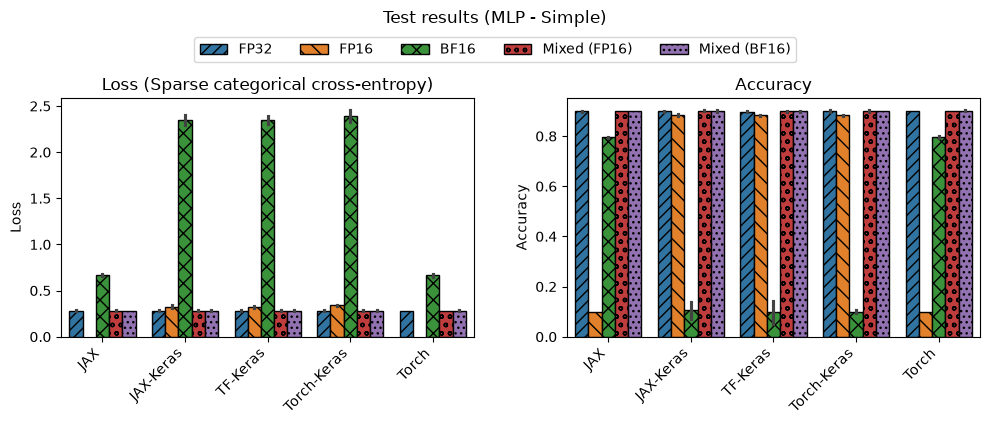

/tmp/ipykernel_1794546/3451327317.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_1794546/3451327317.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")


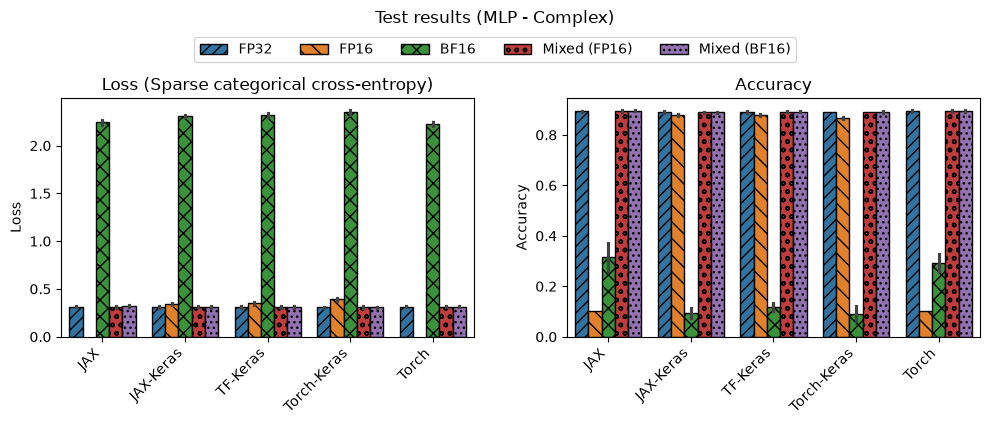

/tmp/ipykernel_1794546/3451327317.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_1794546/3451327317.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")


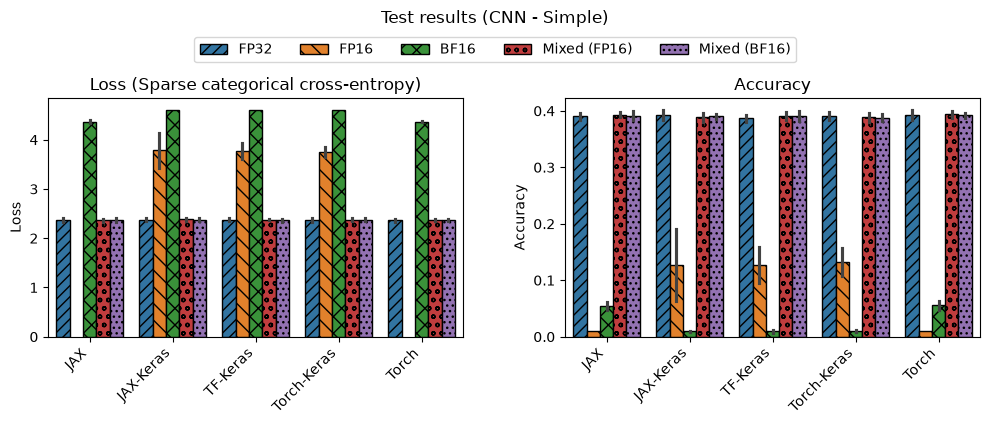

/tmp/ipykernel_1794546/3451327317.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_1794546/3451327317.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")


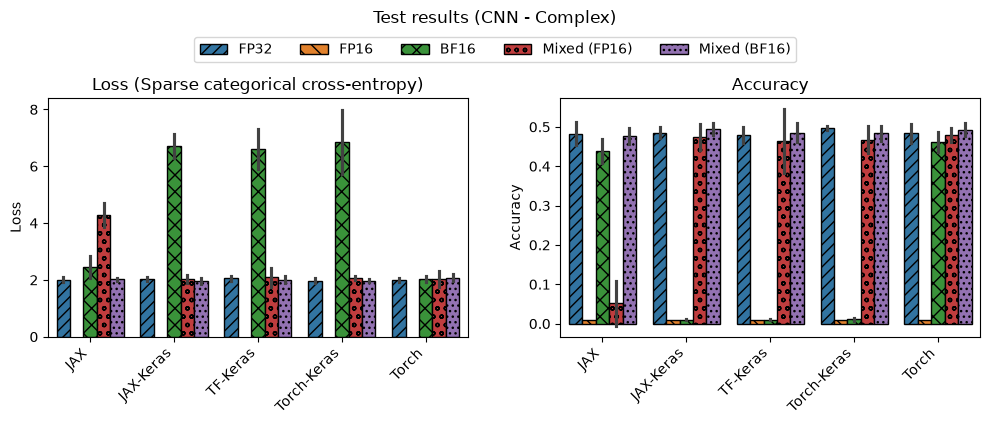

/tmp/ipykernel_1794546/3451327317.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_1794546/3451327317.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")


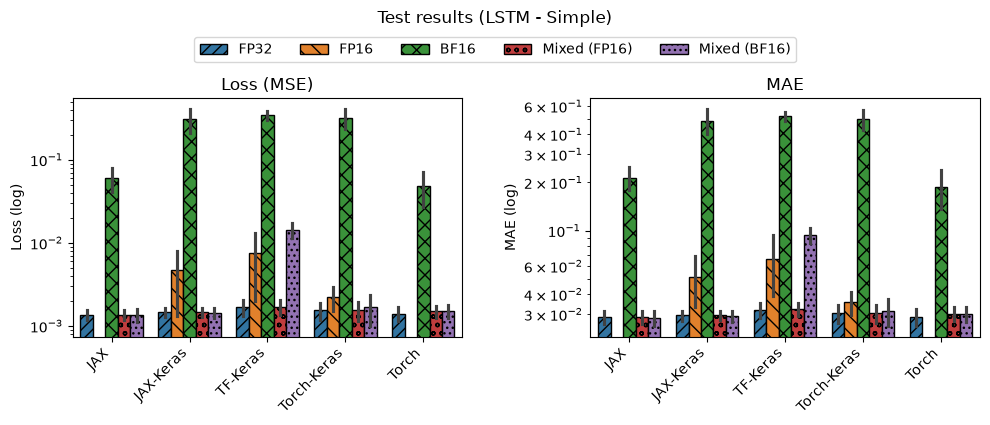

/tmp/ipykernel_1794546/3451327317.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_1794546/3451327317.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")


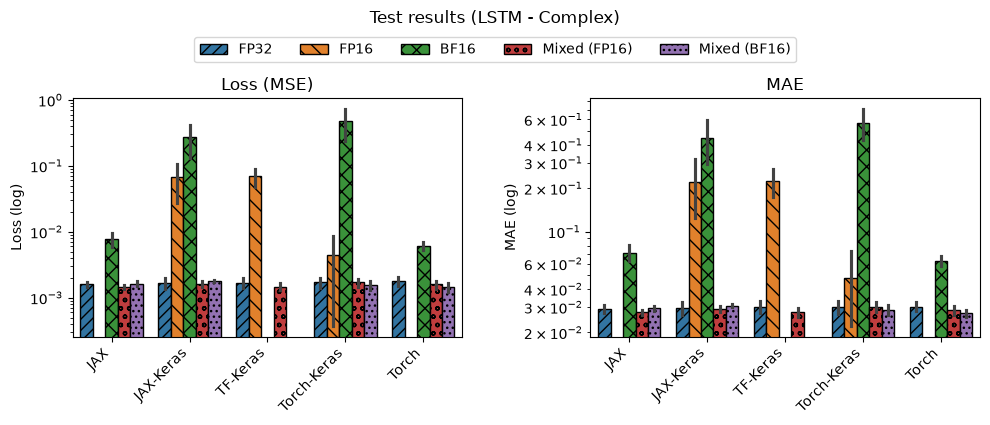

/tmp/ipykernel_1794546/3451327317.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_1794546/3451327317.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")


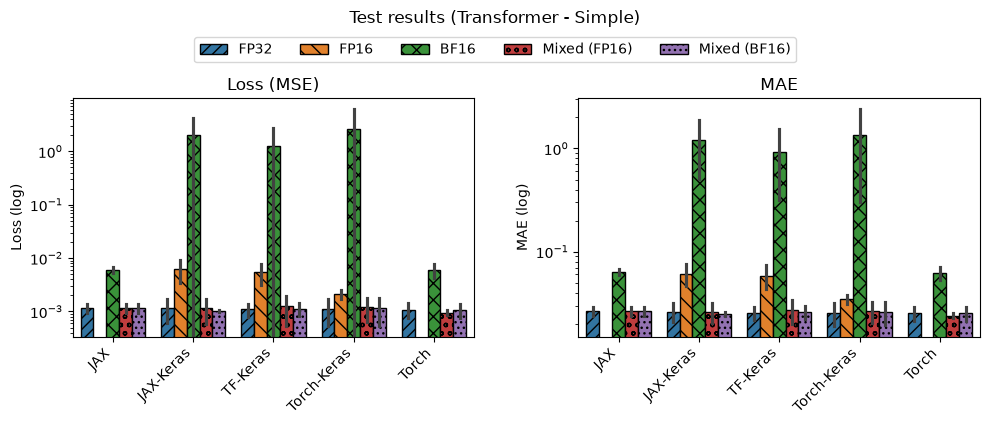

/tmp/ipykernel_1794546/3451327317.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_1794546/3451327317.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")


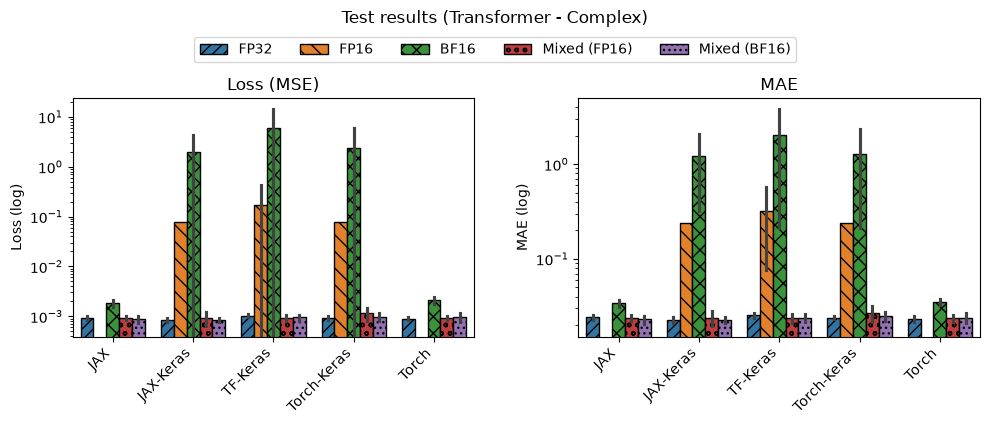

In [63]:
mapping = {
    "mlp": ("Sparse categorical cross-entropy", "Accuracy", False),
    "cnn": ("Sparse categorical cross-entropy", "Accuracy", False),
    "lstm": ("MSE", "MAE", True),
    "transformer": ("MSE", "MAE", True),
}

for model in orders["model_type"]:
    for complexity in orders["model_complexity"]:
        loss_name, metric_name, log = mapping[model]
        plot_test_results(test_metric_df, model, complexity, loss_name, metric_name, log)

In [69]:
compare_paired("test_loss_mean", "model_type=='lstm' and model_complexity=='simple'")

,test_loss_mean,pairs,diff_%,ci_low_%,ci_high_%,p,min_%,max_%
backend,,,,,,,,
jax,0.003523,4,0.0,NaN,NaN,NaN,NaN,NaN
torch,0.003528,4,0.1,-12.3,14.3,9.822241e-01,-19.5,11.1
jax-keras,0.005520,4,56.7,40.5,74.8,8.404001e-08,6.0,405.0
torch-keras,0.005973,4,69.6,48.0,94.3,5.677344e-08,12.5,425.5
tf-keras,0.010897,4,209.3,178.2,244.0,1.817084e-16,22.9,962.2


In [65]:
# For LSTM, half precision shows punctual bad results that distort the mean
compare("test_loss_mean", "model_type=='lstm' and model_complexity=='simple' and precision in ['fp32', 'mixed_fp16', 'mixed_bf16']")

,test_loss_mean,diff_%
backend,,
jax,0.001364,0.0
jax-keras,0.001447,6.1
torch,0.001469,7.8
torch-keras,0.001587,16.4
tf-keras,0.005913,333.7


## Summary

In [72]:
metrics_cfg = {
        "training_time": {
            "label": "Training time (s)",
            "best": "min"
        },
        "testing_time": {
            "label": "Testing time (s)",
            "best": "min"
        },
        "train_gpu_utilization_mean": {
            "label": "Mean GPU usage (\\%)",
            "best": "max"
        },
        "train_cc_gpu_energy": {
            "label": "GPU energy (kJ)",
            "best": "min"
        },
        "train_cc_energy": {
            "label": "Total energy (kJ)",
            "best": "min"
        },
        "test_loss_mean": {
            "label": "Test loss",
            "best": "min"
        },
        "test_metric_mean": {
            "label": "Test metric",
            "best": "max"
        }
    }

energy_caption = (
    " Total energy is the CPU, GPU and RAM energy measured by CodeCarbon during training, "
    "and GPU energy is its GPU part."
)

In [73]:
summary_df = variability_df[experiment_config[:-1] + ["metric", "mean", "ci_half"]]
summary_df = summary_df[summary_df["metric"].isin(metrics_cfg.keys())].reset_index(drop=True)
summary_df.head()

,backend,model_type,model_complexity,precision,metric,mean,ci_half
0,jax,cnn,complex,bf16,training_time,566.641875,6.018032
1,jax,cnn,complex,fp16,training_time,537.684504,12.877259
2,jax,cnn,complex,fp32,training_time,891.125948,5.425406
3,jax,cnn,complex,mixed_bf16,training_time,581.590327,17.245122
4,jax,cnn,complex,mixed_fp16,training_time,573.518641,13.757374


In [74]:
label_map = {k: v["label"] for k, v in metrics_cfg.items()}
ordered_labels = [v["label"] for v in metrics_cfg.values()]

In [75]:
def get_pivot_table(df: pd.DataFrame, index: list[str], values: list[str]) -> pd.DataFrame:
    df["metric"] = df["metric"].map(label_map)

    pivot_table = df.pivot_table(
        index=index,
        columns="metric",
        values=values,
        aggfunc="first",
        observed=True,
    )

    # Reorder columns
    ordered_cols = [(val, metric) for metric in ordered_labels for val in values]
    return pivot_table.loc[:, ordered_cols]

In [76]:
def best_direction(model: str, metric: str) -> str:
    # Lower is better for the MAE of the regression models
    if model in regression_models and metric == "test_metric_mean":
        return "min"
    return metrics_cfg[metric]["best"]


def tests_vs_best(model: str, complexity: str, metric: str) -> pd.DataFrame:
    """Welch's t-test of each eligible configuration against the best one, in the whole table
    ("overall" family) and within each backend, with Holm's correction inside each family."""
    seeds_df = (
        metrics_df.merge(eligible_df.query("eligible"), on=experiment_config[:-1])
        .query("model_type==@model and model_complexity==@complexity")
    )
    values = seeds_df.groupby(["backend", "precision"])[metric].apply(np.asarray)
    means = values.map(np.mean)
    direction = best_direction(model, metric)

    families = [("overall", means)] + list(means.groupby(level="backend"))
    results = []

    for family, family_means in families:
        ref = family_means.idxmin() if direction == "min" else family_means.idxmax()
        keys = family_means.index

        tests = pd.DataFrame([welch(values[key], values[ref]) for key in keys], index=keys)
        others = keys != ref
        tests.loc[~others, ["ci_low_%", "ci_high_%", "p"]] = np.nan
        tests["p_holm"] = np.nan
        tests.loc[others, "p_holm"] = holm(tests.loc[others, "p"])
        tests["tied"] = ~others | (tests["p_holm"] >= ALPHA)

        tests = tests.assign(
            family=family,
            mean=family_means,
            ci_half=[ci_half(values[key]) for key in keys],
            ref_backend=ref[0],
            ref_precision=ref[1],
        )
        results.append(tests.reset_index())

    columns = [
        "model_type", "model_complexity", "metric", "family", "backend", "precision", "mean", "ci_half",
        "ref_backend", "ref_precision", "diff_%", "ci_low_%", "ci_high_%", "p", "p_holm", "tied",
    ]
    return pd.concat(results, ignore_index=True).assign(
        model_type=model, model_complexity=complexity, metric=metric
    )[columns]

In [77]:
tests_df = pd.concat(
    [
        tests_vs_best(model, complexity, metric)
        for model in orders["model_type"]
        for complexity in orders["model_complexity"]
        for metric in metrics_cfg
    ],
    ignore_index=True,
)
tests_df.to_csv(f"{ARTIFACTS_PATH}/statistical_tests.csv", index=False, float_format="%.6g")

# Bold: tied with the best of the table; underline: tied with the best of its backend
marks_df = (
    tests_df.assign(
        bold=tests_df["tied"] & (tests_df["family"] == "overall"),
        underline=tests_df["tied"] & (tests_df["family"] != "overall"),
    )
    .groupby(experiment_config[:-1] + ["metric"])[["bold", "underline"]].any()
    .reset_index()
)

tests_df.head()

,model_type,model_complexity,metric,family,backend,precision,mean,ci_half,ref_backend,ref_precision,diff_%,ci_low_%,ci_high_%,p,p_holm,tied
0,mlp,simple,training_time,overall,jax,bf16,182.355337,9.801910,tf-keras,mixed_bf16,60.275111,51.744607,68.805616,2.382687e-05,2.147558e-04,False
1,mlp,simple,training_time,overall,jax,fp32,184.228487,4.088031,tf-keras,mixed_bf16,61.921453,58.364739,65.478168,1.494549e-08,2.839643e-07,False
2,mlp,simple,training_time,overall,jax,mixed_bf16,234.386057,7.134108,tf-keras,mixed_bf16,106.005769,99.828141,112.183397,2.539321e-07,4.062913e-06,False
3,mlp,simple,training_time,overall,jax,mixed_fp16,231.331356,8.485640,tf-keras,mixed_bf16,103.320942,95.952648,110.689235,9.652824e-07,1.447924e-05,False
4,mlp,simple,training_time,overall,jax-keras,fp16,137.809855,10.949565,tf-keras,mixed_bf16,21.123353,11.579051,30.667655,3.144844e-03,1.572422e-02,False


In [78]:
def format_cell(mean: float, ci, bold: bool, underline: bool, sci_notation: bool) -> str:
    if pd.isna(mean):
        return "--"

    def number(value: float) -> str:
        return f"{value:.2e}".replace("e-0", "e-") if sci_notation else f"{value:.2f}"

    def decorate(text: str) -> str:
        if underline:
            text = f"\\underline{{{text}}}"

        if bold:
            text = f"\\textbf{{{text}}}"

        return text

    # The interval goes in a second line, so that the columns don't get wider
    lines = [decorate(number(mean))]

    if ci is not None and pd.notna(ci):
        lines.append(decorate(f"$\\pm${number(ci)}"))

    content = " \\\\ ".join(lines)
    return f"\\makecell[r]{{{content}}}"

In [79]:
def format_table(pivot_table: pd.DataFrame, sci_notation: list[str], show_ci: bool = True) -> pd.DataFrame:
    latex_table = pd.DataFrame(index=pivot_table.index)

    for metric in ordered_labels:
        columns = pivot_table.xs(metric, axis=1, level="metric")

        latex_table[metric] = [
            format_cell(
                row["mean"],
                row["ci_half"] if show_ci else None,
                row.get("bold", False),
                row.get("underline", False),
                metric in sci_notation,
            )
            for _, row in columns.iterrows()
        ]

    return latex_table

In [80]:
def format_latex(output_path: str, n_columns: int):

    with open(output_path, "r", encoding="utf-8") as f:
        content = f.read()

    result = []
    backends = iter( [l for _,l in labels["backend"].items()] )
    first_line = True

    for line in content.splitlines():
        # Add backend lines for each precision group
        if line.startswith(("FP32", "Simple")):
            backend_line = f"\\textbf{{{next(backends)}}}" + " & " * n_columns + " \\\\"

            if first_line:
                first_line = False
            else:
                backend_line = "\\\\ " + backend_line

            result.append(backend_line)

        # Replace alignment config
        line = line.replace(
            f"begin{{tabular}}{{{'l' * (n_columns + 1)}}}",
            f"begin{{tabular}}{{l{'r' * n_columns}}}"
        )

        result.append(line)

    with open(output_path, "w", encoding="utf-8") as f:
        f.write("\n".join(result))

In [81]:
def save_to_latex(latex_table: pd.DataFrame, output_path: str, caption: str, label: str) -> pd.DataFrame:
    # Save to latex
    latex_table.to_latex(
        output_path,
        index=True,
        multirow=True,
        escape=False,
        caption=caption,
        label=label
    )

    format_latex(output_path, n_columns=len(latex_table.columns))

    return latex_table

In [82]:
def summary_table(df: pd.DataFrame, model: str, complexity: str, show_best: bool = True, sci_notation: list[str] = []) -> pd.DataFrame:
    flags = ["bold", "underline", "eligible"]
    plot_df = (
        df.query("model_type==@model and model_complexity==@complexity")
        .merge(marks_df, on=experiment_config[:-1] + ["metric"], how="left")
        .merge(eligible_df, on=experiment_config[:-1], how="left")
    )
    plot_df[flags] = plot_df[flags].fillna(False).astype(bool)

    if not show_best:
        plot_df[["bold", "underline"]] = False

    precision_labels = {**labels["precision"], "mixed_fp16": "Mixed-FP16", "mixed_bf16": "Mixed-BF16"}
    plot_df = add_labels(plot_df, labels={**labels, "precision": precision_labels})

    # Create the table
    pivot_table = get_pivot_table(plot_df, index=["backend", "precision"], values=["mean", "ci_half", *flags])
    latex_table = format_table(pivot_table, sci_notation)

    # Configurations excluded from the comparison are marked in the precision
    eligible = pivot_table["eligible"].any(axis=1)
    latex_table.index = pd.MultiIndex.from_tuples(
        [(backend, precision if ok else f"{precision}$^\\dagger$") for (backend, precision), ok in zip(latex_table.index, eligible)]
    )

    # Rename index columns and remove framework (will be added later)
    latex_table = latex_table.rename_axis(index=["Framework", "Precision"], columns="")
    latex_table = latex_table.droplevel("Framework")

    # Caption
    model = labels["model_type"][model]
    caption = (
        f"Summary of results for {model} ({complexity}). "
        f"Values are the mean across the seeds and, below it, the half-width of its {CI_LEVEL:.0%} "
        "confidence interval (Student's t)."
    ).replace("%", "\\%")

    caption += energy_caption

    if model == "LSTM":
        caption += " JAX-Keras uses the cuDNN LSTM in FP32, the only precision it supports in JAX."

    if show_best:
        caption += (
            " Values in \\textbf{bold} are the best of the table or not significantly different from it, "
            "and \\underline{underlined} values are the same within each framework "
            f"(Welch's t-test against the best, Holm-corrected, $\\alpha = {ALPHA}$)."
        )

    if not eligible.all():
        caption += (
            " Configurations marked with $^\\dagger$ did not train in every seed (NaN test loss, or no "
            "improvement of the validation loss after the first epoch) and are excluded from the comparison."
        )

    output_path = f"{LATEX_PATH}/summary_table_{model}_{complexity}.tex"
    label=f"tab:summary_{model}_{complexity}"

    latex_table = save_to_latex(latex_table, output_path, caption, label)

    return latex_table

In [83]:
ordered_labels

['Training time (s)',
 'Testing time (s)',
 'Mean GPU usage (\\%)',
 'GPU energy (kJ)',
 'Total energy (kJ)',
 'Test loss',
 'Test metric']

In [84]:
#summary_table(summary_df, "mlp", "complex")
summary_table(summary_df, "lstm", "simple", sci_notation=["Test loss"])

,Training time (s),Testing time (s),Mean GPU usage (\%),GPU energy (kJ),Total energy (kJ),Test loss,Test metric
Precision,,,,,,,
FP32,\makecell[r]{\underline{343.08} \\ \underline{...,\makecell[r]{\underline{0.97} \\ \underline{$\...,\makecell[r]{88.61 \\ $\pm$0.65},\makecell[r]{25.14 \\ $\pm$0.25},\makecell[r]{\underline{66.16} \\ \underline{$...,\makecell[r]{\textbf{\underline{1.37e-3}} \\ \...,\makecell[r]{\textbf{\underline{0.03}} \\ \tex...
FP16$^\dagger$,\makecell[r]{338.86 \\ $\pm$2.08},\makecell[r]{0.93 \\ $\pm$0.02},\makecell[r]{89.13 \\ $\pm$0.72},\makecell[r]{24.72 \\ $\pm$0.14},\makecell[r]{65.14 \\ $\pm$0.34},--,--
BF16,\makecell[r]{348.28 \\ $\pm$1.87},\makecell[r]{\underline{1.03} \\ \underline{$\...,\makecell[r]{\textbf{\underline{90.77}} \\ \te...,\makecell[r]{25.44 \\ $\pm$0.13},\makecell[r]{66.93 \\ $\pm$0.40},\makecell[r]{6.08e-2 \\ $\pm$1.97e-2},\makecell[r]{0.21 \\ $\pm$0.04}
Mixed-FP16,\makecell[r]{\underline{341.22} \\ \underline{...,\makecell[r]{\underline{1.01} \\ \underline{$\...,\makecell[r]{89.13 \\ $\pm$0.62},\makecell[r]{\underline{24.89} \\ \underline{$...,\makecell[r]{\underline{65.60} \\ \underline{$...,\makecell[r]{\textbf{\underline{1.37e-3}} \\ \...,\makecell[r]{\textbf{\underline{0.03}} \\ \tex...
Mixed-BF16,\makecell[r]{350.74 \\ $\pm$3.29},\makecell[r]{1.06 \\ $\pm$0.06},\makecell[r]{\textbf{\underline{90.63}} \\ \te...,\makecell[r]{25.63 \\ $\pm$0.23},\makecell[r]{67.42 \\ $\pm$0.68},\makecell[r]{\textbf{\underline{1.35e-3}} \\ \...,\makecell[r]{\textbf{\underline{0.03}} \\ \tex...
FP32,\makecell[r]{\underline{150.51} \\ \underline{...,\makecell[r]{\underline{0.55} \\ \underline{$\...,\makecell[r]{63.01 \\ $\pm$2.03},\makecell[r]{\underline{10.78} \\ \underline{$...,\makecell[r]{\underline{32.58} \\ \underline{$...,\makecell[r]{\textbf{\underline{1.45e-3}} \\ \...,\makecell[r]{\textbf{\underline{0.03}} \\ \tex...
FP16,\makecell[r]{304.53 \\ $\pm$1.88},\makecell[r]{0.97 \\ $\pm$0.09},\makecell[r]{86.65 \\ $\pm$0.81},\makecell[r]{22.09 \\ $\pm$0.18},\makecell[r]{58.90 \\ $\pm$0.36},\makecell[r]{\textbf{\underline{4.66e-3}} \\ \...,\makecell[r]{\textbf{\underline{0.05}} \\ \tex...
BF16$^\dagger$,\makecell[r]{323.90 \\ $\pm$8.46},\makecell[r]{0.98 \\ $\pm$0.07},\makecell[r]{86.80 \\ $\pm$1.15},\makecell[r]{23.49 \\ $\pm$0.66},\makecell[r]{62.48 \\ $\pm$1.56},\makecell[r]{3.07e-1 \\ $\pm$9.93e-2},\makecell[r]{0.49 \\ $\pm$0.09}
Mixed-FP16,\makecell[r]{294.62 \\ $\pm$1.88},\makecell[r]{0.83 \\ $\pm$0.09},\makecell[r]{\textbf{\underline{89.52}} \\ \te...,\makecell[r]{21.43 \\ $\pm$0.13},\makecell[r]{57.40 \\ $\pm$0.41},\makecell[r]{\textbf{\underline{1.45e-3}} \\ \...,\makecell[r]{\textbf{\underline{0.03}} \\ \tex...


In [85]:
for model in orders["model_type"]:
    for complexity in orders["model_complexity"]:
        t = summary_table(summary_df, model, complexity, sci_notation=["Test loss", "Test metric"] if model in regression_models else [])

### Comparison summary table

In [86]:
summary_df.query("model_type=='cnn' and model_complexity=='complex' and backend=='jax' and metric=='test_metric_mean'")

,backend,model_type,model_complexity,precision,metric,mean,ci_half
800,jax,cnn,complex,bf16,test_metric_mean,0.43970,0.030391
801,jax,cnn,complex,fp16,test_metric_mean,0.01000,0.000000
802,jax,cnn,complex,fp32,test_metric_mean,0.48256,0.029725
803,jax,cnn,complex,mixed_bf16,test_metric_mean,0.47682,0.020655
804,jax,cnn,complex,mixed_fp16,test_metric_mean,0.05164,0.057253


In [87]:
comparison_df = summary_df.groupby(experiment_config[:-2] + ["metric"])[["mean"]].median().reset_index()
comparison_df.head()

,backend,model_type,model_complexity,metric,mean
0,jax,cnn,complex,test_loss_mean,2.231776
1,jax,cnn,complex,test_metric_mean,0.439700
2,jax,cnn,complex,testing_time,0.475036
3,jax,cnn,complex,train_cc_energy,212.849410
4,jax,cnn,complex,train_cc_gpu_energy,130.779396


In [88]:
def comparison_summary_table(df: pd.DataFrame, model: str, sci_notation: list[str] = []):
    plot_df = df.query("model_type==@model")
    plot_df = add_labels(plot_df)
    plot_df = plot_df.sort_values(by=["backend", "model_complexity"])

    # Create the table
    pivot_table = get_pivot_table(plot_df, index=["backend", "model_complexity"], values=["mean"])
    latex_table = format_table(pivot_table, sci_notation, show_ci=False)

    # Rename index columns
    latex_table = latex_table.rename_axis(index=["Framework", "Version"], columns="")
    latex_table = latex_table.droplevel("Framework")

    # Caption
    model = labels["model_type"][model]
    caption = (
        f"Comparison of results for both {model} versions. "
        "Represented values are the median across precision formats of the seed means."
    )

    caption += energy_caption

    if model == "LSTM":
        caption += " JAX-Keras uses the cuDNN LSTM in FP32, the only precision it supports in JAX."

    # Save to latex
    output_path = f"{LATEX_PATH}/comparison_table_{model}.tex"
    label=f"tab:comparison_{model}"
    latex_table = save_to_latex(latex_table, output_path, caption, label)

    return latex_table

In [89]:
comparison_summary_table(comparison_df, "cnn")
#comparison_summary_table(comparison_df, "lstm", sci_notation=["Test loss"])

,Training time (s),Testing time (s),Mean GPU usage (\%),GPU energy (kJ),Total energy (kJ),Test loss,Test metric
Version,,,,,,,
Simple,\makecell[r]{210.08},\makecell[r]{0.35},\makecell[r]{15.75},\makecell[r]{15.83},\makecell[r]{47.05},\makecell[r]{2.37},\makecell[r]{0.39}
Complex,\makecell[r]{573.52},\makecell[r]{0.48},\makecell[r]{92.23},\makecell[r]{130.78},\makecell[r]{212.85},\makecell[r]{2.23},\makecell[r]{0.44}
Simple,\makecell[r]{162.60},\makecell[r]{0.29},\makecell[r]{21.13},\makecell[r]{12.09},\makecell[r]{38.58},\makecell[r]{2.38},\makecell[r]{0.39}
Complex,\makecell[r]{552.23},\makecell[r]{0.48},\makecell[r]{95.89},\makecell[r]{139.54},\makecell[r]{220.33},\makecell[r]{2.03},\makecell[r]{0.47}
Simple,\makecell[r]{125.37},\makecell[r]{0.38},\makecell[r]{22.41},\makecell[r]{9.31},\makecell[r]{23.61},\makecell[r]{2.38},\makecell[r]{0.39}
Complex,\makecell[r]{689.71},\makecell[r]{0.69},\makecell[r]{72.69},\makecell[r]{147.41},\makecell[r]{228.01},\makecell[r]{2.07},\makecell[r]{0.46}
Simple,\makecell[r]{310.14},\makecell[r]{0.39},\makecell[r]{9.05},\makecell[r]{21.24},\makecell[r]{71.65},\makecell[r]{2.38},\makecell[r]{0.39}
Complex,\makecell[r]{4670.75},\makecell[r]{0.79},\makecell[r]{20.11},\makecell[r]{443.98},\makecell[r]{983.79},\makecell[r]{2.02},\makecell[r]{0.47}
Simple,\makecell[r]{249.65},\makecell[r]{0.31},\makecell[r]{18.74},\makecell[r]{17.21},\makecell[r]{58.03},\makecell[r]{2.37},\makecell[r]{0.39}


In [90]:
for model in orders["model_type"]:
    t = comparison_summary_table(comparison_df, model, sci_notation=["Test loss", "Test metric"] if model in regression_models else [])

# Comparison

## Correlation

In [91]:
results = []

for energy in ["train_cc_gpu_energy", "train_cc_energy"]:
    for model in orders["model_type"]:
        group = metrics_df.query("model_type==@model")

        X = group[["training_time"]].values
        y = group[energy].values
        regression = LinearRegression().fit(X, y)

        results.append({
            "energy": energy,
            "model_type": model,
            "correlation": group["training_time"].corr(group[energy]),
            "mean_power_W": regression.coef_[0] * 1000,  # kJ/s -> W
            "intercept_kJ": regression.intercept_,
            "R2": regression.score(X, y)
        })

results_df = pd.DataFrame(results)

results_df.round(5)

,energy,model_type,correlation,mean_power_W,intercept_kJ,R2
0,train_cc_gpu_energy,mlp,0.97956,69.34164,0.07780,0.95953
1,train_cc_gpu_energy,cnn,0.91371,95.52852,32.63390,0.83486
2,train_cc_gpu_energy,lstm,0.95923,82.46832,2.27867,0.92013
3,train_cc_gpu_energy,transformer,0.84526,123.58004,21.21068,0.71446
4,train_cc_energy,mlp,0.99182,247.59731,-4.95705,0.98370
5,train_cc_energy,cnn,0.97966,209.41092,42.33106,0.95973
6,train_cc_energy,lstm,0.99246,195.64013,4.41967,0.98498
7,train_cc_energy,transformer,0.95070,237.23902,23.12350,0.90384


## Comparison plots

### Model versions comparison

In [92]:
summary_df.head()

,backend,model_type,model_complexity,precision,metric,mean,ci_half
0,jax,cnn,complex,bf16,training_time,566.641875,6.018032
1,jax,cnn,complex,fp16,training_time,537.684504,12.877259
2,jax,cnn,complex,fp32,training_time,891.125948,5.425406
3,jax,cnn,complex,mixed_bf16,training_time,581.590327,17.245122
4,jax,cnn,complex,mixed_fp16,training_time,573.518641,13.757374


In [93]:
complex_comp_df = summary_df.pivot_table(
    index=["model_type", "backend", "precision", "metric"],
    columns="model_complexity",
    values="mean"
).reset_index()

complex_comp_df["comp"] = (complex_comp_df["complex"] / complex_comp_df["simple"]) - 1

complex_comp_df.head()

model_complexity,model_type,backend,precision,metric,complex,simple,comp
0,cnn,jax,bf16,test_loss_mean,2.448118,4.369637,-0.439743
1,cnn,jax,bf16,test_metric_mean,0.439700,0.054700,7.038391
2,cnn,jax,bf16,testing_time,0.413319,0.323207,0.278804
3,cnn,jax,bf16,train_cc_energy,214.068627,45.807005,3.673273
4,cnn,jax,bf16,train_cc_gpu_energy,133.355716,14.753362,8.039005


In [94]:
def version_increments(df: pd.DataFrame, model: str) -> pd.DataFrame:
    # Increment (%) of the complex version over the simple one, median over precisions
    return df.query("model_type==@model").groupby(["backend", "metric"])["comp"].median().mul(100).reset_index()


def plot_version_increments(df: pd.DataFrame, model: str):
    plot_df = add_labels(version_increments(df, model))

    # Remove units from labels
    clean_labels = {
        key: re.sub(r'\s*\(.*?\)', '', value).strip()
        for key, value in label_map.items()
    }
    plot_df["metric"] = plot_df["metric"].map(clean_labels)

    plot = sns.catplot(
        data=plot_df,
        x="metric",
        y="comp",
        kind="bar",
        hue="backend",
        order=clean_labels.values(),
        legend="auto"
    )
    
    add_patterns(plot)
    set_size(plot, width=10)

    model = labels["model_type"][model]

    add_title(plot, f"Metric increments of {model} complex over simple version")
    plot._legend.set_title(r"$\bf{Framework}$")
    plot._legend.set_loc("upper right")
    plot._legend.set_bbox_to_anchor((0.98, 0.93))

    plot.set_axis_labels("Metric", "Increment (%)")
    plot.set_xticklabels(clean_labels.values())

    plt.tight_layout()
    save_plot(plot, f"{model}/version_increments_{model}")

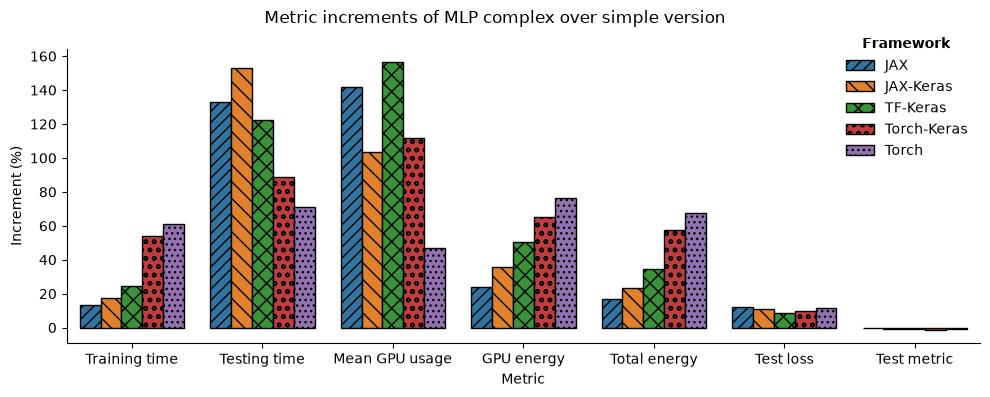

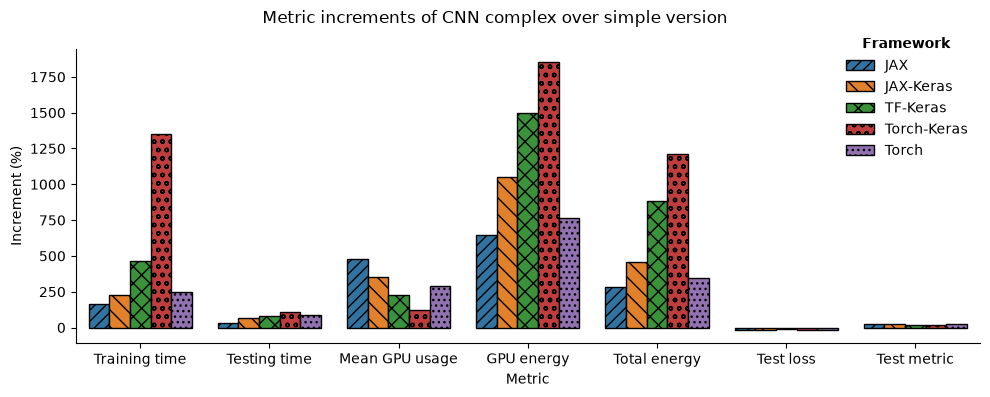

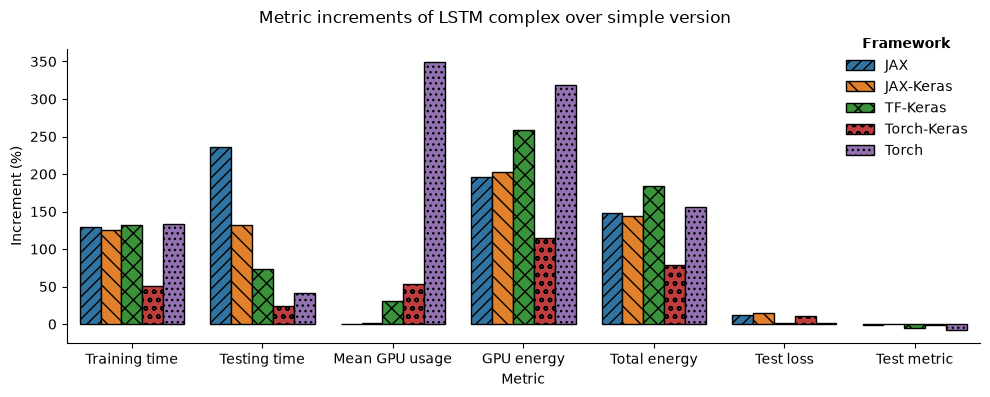

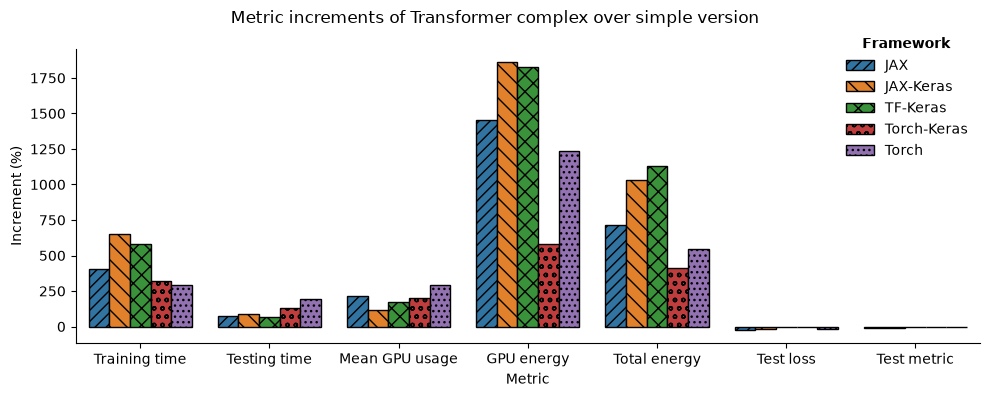

In [95]:
for model in orders["model_type"]:
    plot_version_increments(complex_comp_df, model)

In [96]:
(
    version_increments(complex_comp_df, "lstm")
    .pivot(index="backend", columns="metric", values="comp")
    .reindex(index=orders["backend"], columns=list(label_map))
)

metric,training_time,testing_time,train_gpu_utilization_mean,train_cc_gpu_energy,train_cc_energy,test_loss_mean,test_metric_mean
backend,,,,,,,
jax,130.040486,236.098888,-0.137846,196.532118,147.929152,12.191881,-1.106334
jax-keras,125.409624,131.934680,1.426194,203.013697,144.653261,15.310664,0.393004
tf-keras,131.870176,73.913373,30.368399,258.782636,183.408334,0.849882,-5.143278
torch-keras,50.732465,24.616221,53.926478,115.288724,78.716815,10.314463,-0.758454
torch,133.403353,40.840508,348.835296,319.180041,156.583383,1.540164,-7.474991


## Vs. plots

In [97]:
# Keep only configurations whose runs all trained (eligible_df); a seed still running does not exclude them
success_df = metrics_df[experiment_config].merge(
    eligible_df.query("eligible")[experiment_config[:-1]], on=experiment_config[:-1]
)
success_df = exp_config_category(success_df)
success_df.head()

,backend,model_type,model_complexity,precision,seed
0,jax,cnn,complex,bf16,42
1,jax,cnn,complex,bf16,43
2,jax,cnn,complex,bf16,44
3,jax,cnn,complex,bf16,45
4,jax,cnn,complex,bf16,46


In [98]:
# Seed mean of each configuration
vs_metrics = ["training_time", "train_cc_energy", "train_gpu_utilization_mean", "train_gpu_memory_max"]

vs_df = (
    metrics_df.merge(success_df, on=experiment_config)
    .groupby(experiment_config[:-1])[vs_metrics]
    .mean()
    .reset_index()
)

vs_df.head()

,backend,model_type,model_complexity,precision,training_time,train_cc_energy,train_gpu_utilization_mean,train_gpu_memory_max
0,jax,cnn,complex,bf16,566.641875,214.068627,93.015873,60.647644
1,jax,cnn,complex,fp32,891.125948,351.863413,97.189354,60.645691
2,jax,cnn,complex,mixed_bf16,581.590327,212.849410,91.261403,60.647644
3,jax,cnn,simple,bf16,208.288356,45.807005,16.177618,60.639832
4,jax,cnn,simple,fp32,210.077053,47.053455,19.787252,60.632019


In [99]:
markers = ["o", "X", "P", "^", "v"]
precision_markers = {precision_labels[precision]: marker for precision, marker in zip(orders["precision"], markers)}
precision_markers

{'FP32': 'o',
 'FP16': 'X',
 'BF16': 'P',
 'Mixed (FP16)': '^',
 'Mixed (BF16)': 'v'}

In [100]:
metrics_cfg["train_gpu_memory_max"] = {
    "label": "Max GPU memory (GB)",
    "best": "min"
}

In [101]:
def get_pareto_df(df, metric_x, metric_y, improvement=0): # Minimum % improvement
    cfg_best_x = metrics_cfg[metric_x]["best"]
    cfg_best_y = metrics_cfg[metric_y]["best"]

    # Sort values by config
    df2 = df[[metric_x, metric_y]].sort_values(
        [metric_x, metric_y],
        ascending=[
            cfg_best_x=="min",
            cfg_best_y=="min"
        ]).reset_index(drop=True)
    
    # Prepare vars depending on best type
    if cfg_best_y == "min":
        best_y = np.inf
        threshold = 1 - improvement
    else:
        best_y = -np.inf
        threshold = 1 + improvement

    # Obtain pareto points
    points = []
    for _, row in df2.iterrows():
        is_best = (row[metric_y] < best_y * threshold) if cfg_best_y == "min" else (row[metric_y] > best_y * threshold)

        if is_best:
            points.append((row[metric_x], row[metric_y]))
            best_y = row[metric_y]

    pareto_df = pd.merge(
        df,
        pd.DataFrame(points, columns=[metric_x, metric_y]),
        on=[metric_x, metric_y]
    )

    return pareto_df

# Test pareto
df = pd.DataFrame([(1,3,'a'),(0,1,'b'),(1,2,'c'),(2,5,'d'),(3,2,'e'),(4,1,'f')], columns=['training_time','train_gpu_utilization_mean','filler'])
df = get_pareto_df(df, 'training_time', 'train_gpu_utilization_mean')
df.head()

,training_time,train_gpu_utilization_mean,filler
0,1,3,a
1,0,1,b
2,2,5,d


In [102]:
pareto_color = sns.color_palette("deep")[5]

In [103]:
def make_legend(plot, df):
    
    backend_handles = []
    precision_handles = []

    colors = sns.color_palette(n_colors=5)
    for backend, color in zip(orders["backend"], colors):
        label = labels["backend"][backend]
        backend_handles.append(Line2D([0], [0], marker='o', color='w', label=label, markerfacecolor=color, markersize=10))

    for precision in orders["precision"]:
        if precision not in df["precision"].values:
            continue
        label = labels["precision"][precision]
        marker = precision_markers[label]
        precision_handles.append(Line2D([0], [0], marker=marker, color='black', linestyle='None', label=label, markersize=10))


    ax = plot.axes.flat[0]

    # Backend legend
    title = titles["backend"]
    legend1 = ax.legend(handles=backend_handles, title=rf"$\bf{{ {title} }}$", loc="upper left", bbox_to_anchor=(1.05, 1))
    ax.add_artist(legend1)

    # Precision legend
    title = titles["precision"]
    legend2 = ax.legend(handles=precision_handles, title=rf"$\bf{{ {title} }}$", loc="upper left", bbox_to_anchor=(1.05, 0.6))

In [104]:
def plot_versus(df, model, complexity, metric_x, metric_y, log_x=False, log_y=False):
    df = df.query("model_type == @model and model_complexity == @complexity")

    plot = sns.relplot(
        data=add_labels(df),
        x=metric_x,
        y=metric_y,
        hue="backend",
        style="precision",
        markers=precision_markers,
        legend=False
    )
    
    ax = plot.axes.flat[0]

    # Labels
    model = labels["model_type"][model]
    complexity = labels["model_complexity"][complexity]
    metric_x_label = metrics_cfg[metric_x]["label"].split(" (")[0]
    metric_y_label = metrics_cfg[metric_y]["label"].split(" (")[0]

    add_title(plot, f"{metric_x_label} vs. {metric_y_label} ({model} - {complexity})", 0.92)

    # Set log scales
    axis_x_label = metrics_cfg[metric_x]["label"]
    axis_y_label = metrics_cfg[metric_y]["label"]

    if log_x:
        ax.set(xscale="log")
        axis_x_label = axis_x_label[:-1] + ", log)"
    
    if log_y:
        ax.set(yscale="log")
        axis_y_label = axis_y_label[:-1] + ", log)"

    plot.set_axis_labels(axis_x_label, axis_y_label)

    # Grid
    ax.grid(True, ls=":", alpha=.4)

    make_legend(plot, df)

    
    # Pareto frontier
    pareto_df = get_pareto_df(df, metric_x, metric_y)
    pareto_df = add_labels(pareto_df)

    scatter = sns.scatterplot(
        data=pareto_df,
        x=metric_x,
        y=metric_y,
        hue="backend",
        style="precision",
        markers=precision_markers,
        legend=False,
        ax=ax,
        
        edgecolor=pareto_color,
        linewidth=1,
        zorder=5
    )

    line = sns.lineplot(
        data=pareto_df,
        x=metric_x,
        y=metric_y,
        legend=False,
        ax=ax,
        
        color=pareto_color,
        zorder=-1
    )

    set_size(scatter)
    set_size(line)

    # Add labels with pareto in bold
    texts = []
    for _, row in df.iterrows():
        is_pareto = ((pareto_df[metric_x] == row[metric_x]) & (pareto_df[metric_y] == row[metric_y])).any()
        texts.append(
            ax.text(
                row[metric_x],
                row[metric_y],
                f'{labels["backend"][row.backend]}\n{labels["precision"][row.precision]}',
                fontsize=9,
                fontweight="bold" if is_pareto else "normal",
                zorder=10 if is_pareto else 3
            )
        )
    adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="->", lw=1))
    
    save_plot(plot, f"{model}/vs_{metric_x}_{metric_y}_{model}_{complexity}", format="svg")

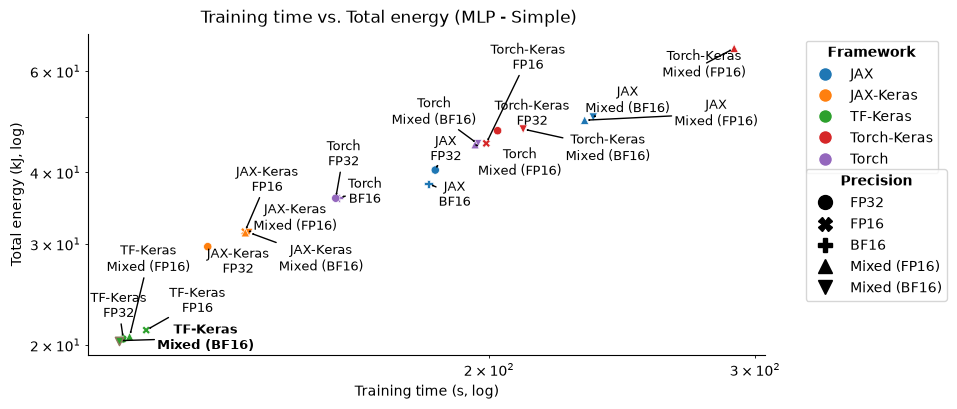

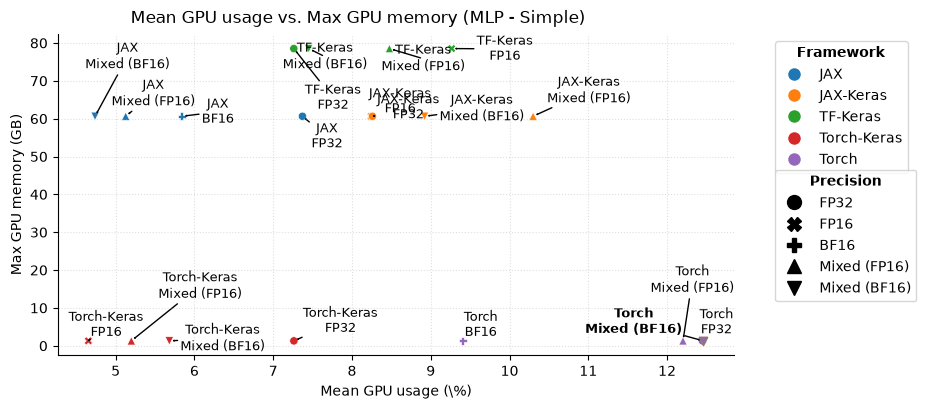

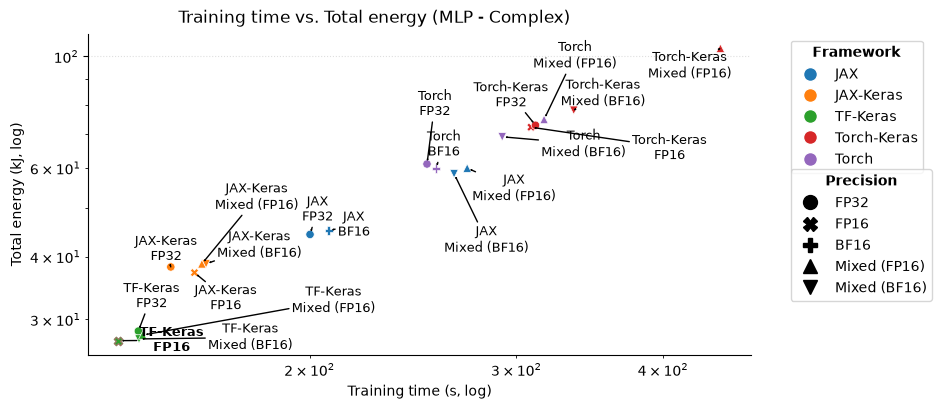

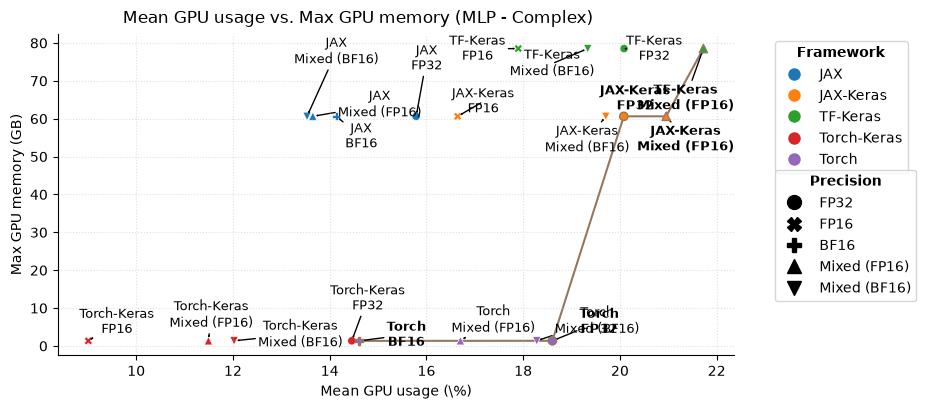

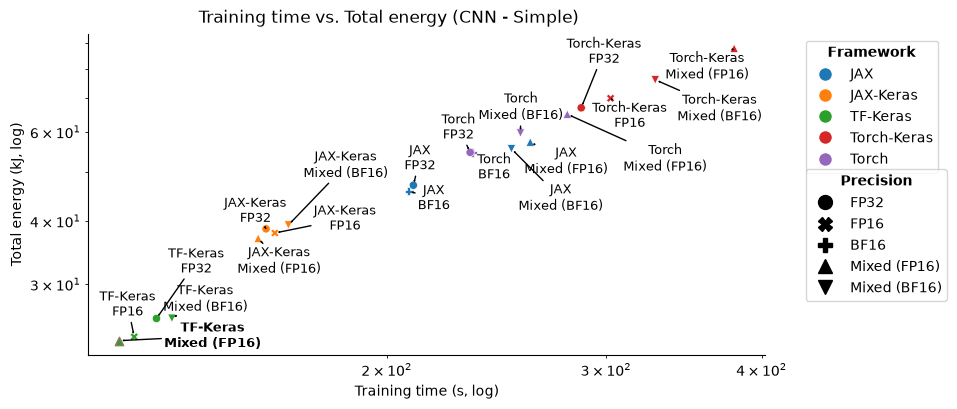

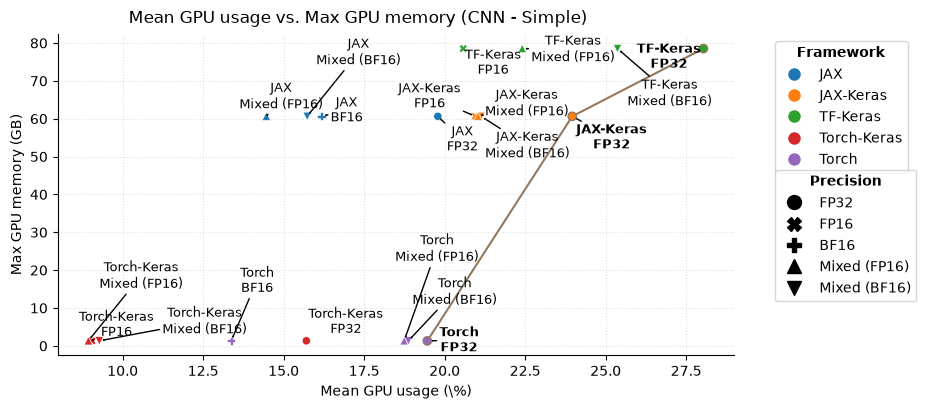

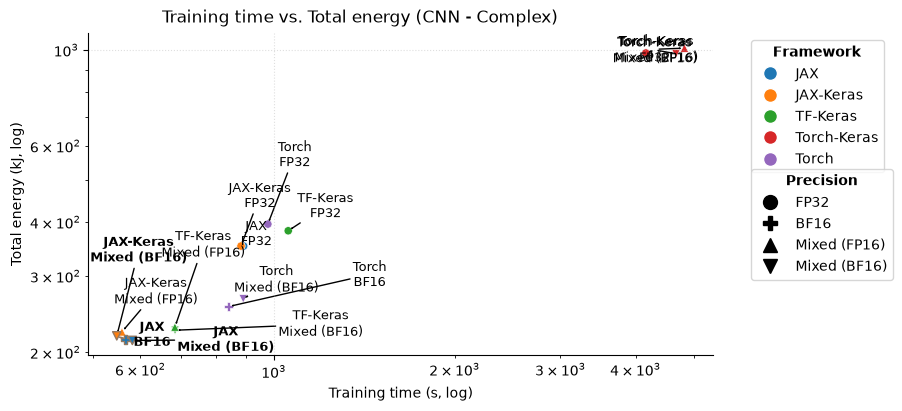

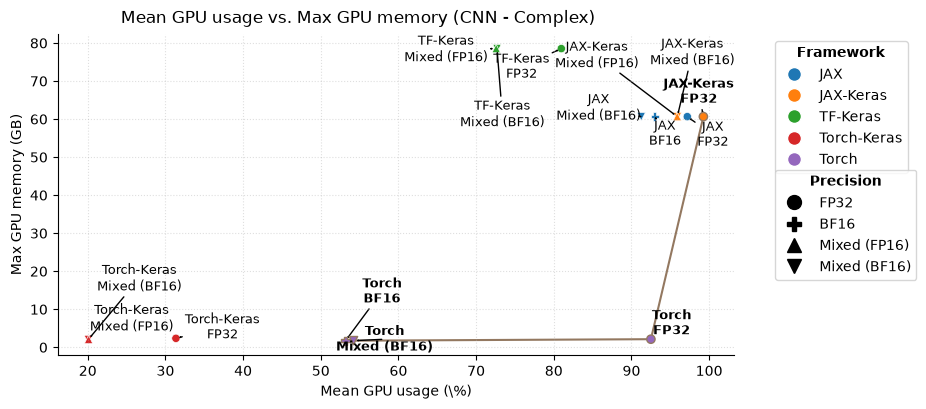

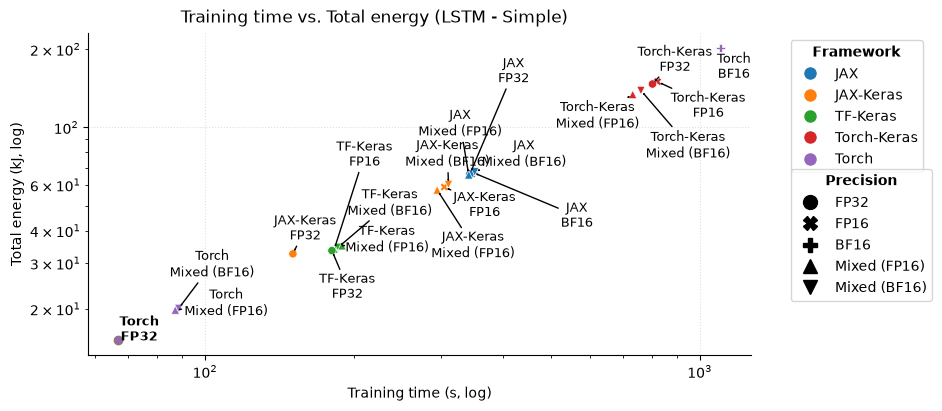

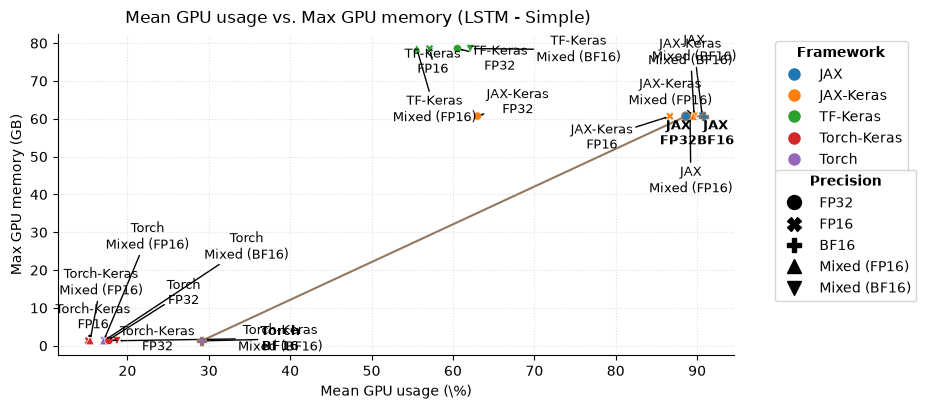

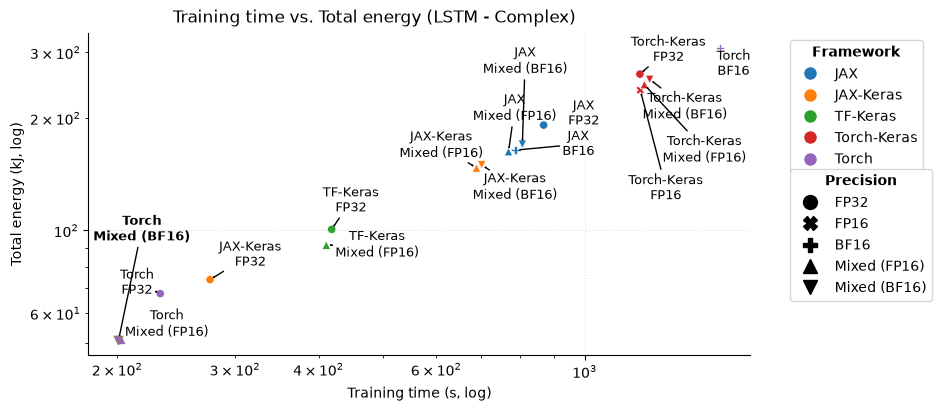

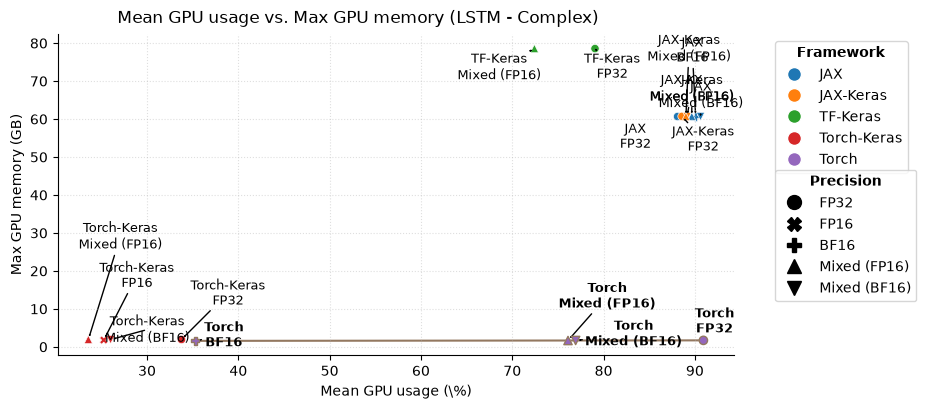

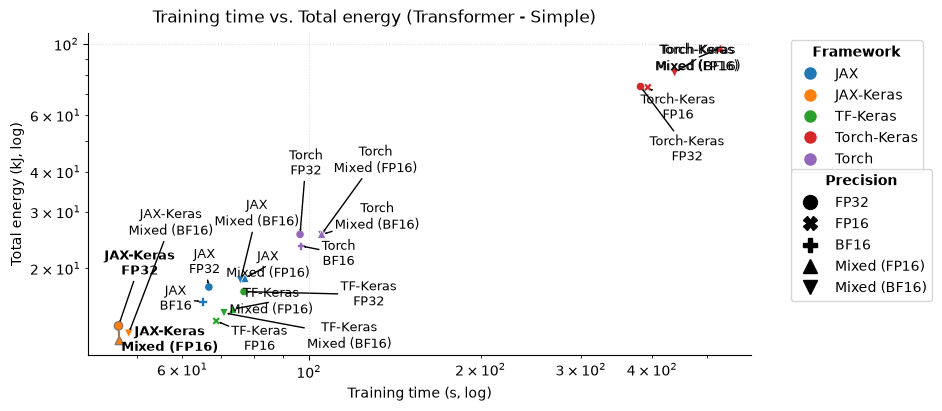

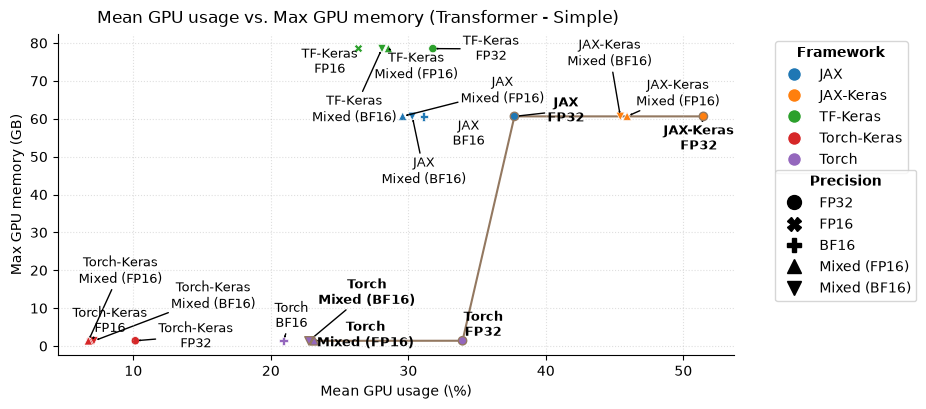

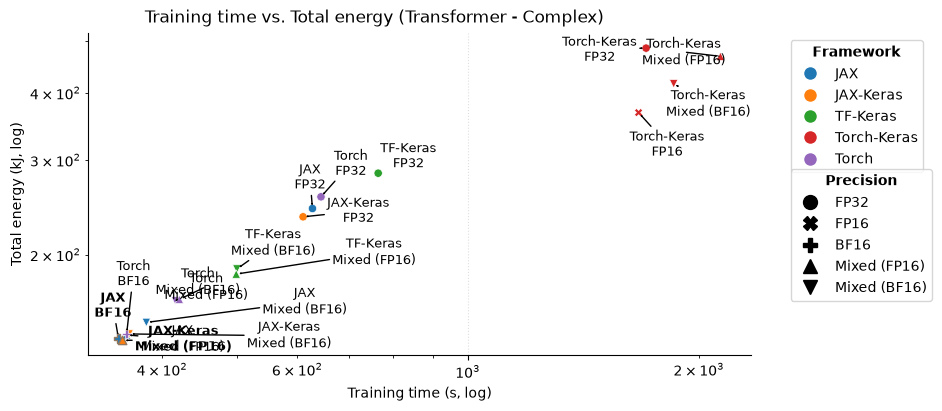

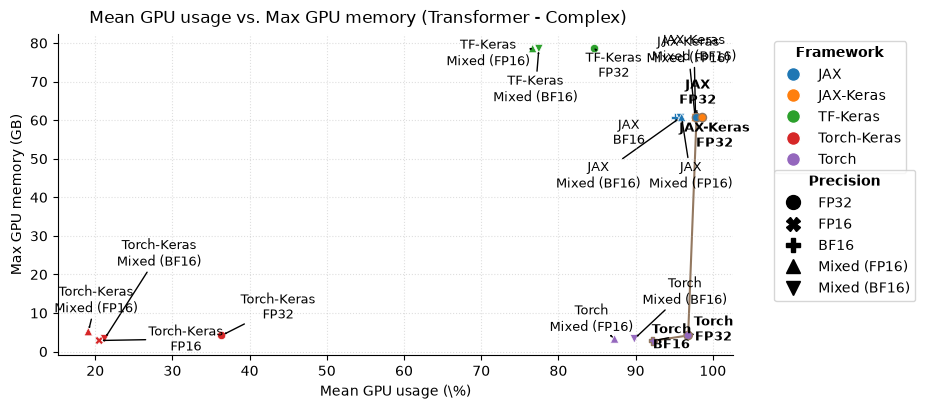

In [105]:
for model in orders["model_type"]:
    for complexity in orders["model_complexity"]:
        plot_versus(vs_df, model, complexity, "training_time", "train_cc_energy", log_x=True, log_y=True)
        plot_versus(vs_df, model, complexity, "train_gpu_utilization_mean", "train_gpu_memory_max")

# JAX-Keras LSTM without cuDNN

In the main comparison, JAX-Keras runs the LSTM with cuDNN in FP32, the only precision cuDNN supports in JAX, and without it in the rest. This section closes the comparison with the FP32 LSTM without cuDNN, which is how Flax runs it (Flax doesn't support cuDNN).

In [106]:
cudnn_metrics_df = pd.concat([
    metrics_df.query("backend == 'jax-keras' and model_type == 'lstm' and precision == 'fp32'").assign(backend=cudnn_backend),
    summarise_runs(no_cudnn_index_df),
])

cudnn_labels = {cudnn_backend: "JAX-Keras (cuDNN)", no_cudnn_backend: "JAX-Keras (no cuDNN)"}

cudnn_cols = [
    "training_time",
    "train_epoch_time_mean",
    "testing_time",
    "train_gpu_utilization_mean",
    "train_cc_energy",
    "test_loss_mean",
    "test_metric_mean",
]

(
    cudnn_metrics_df
    .groupby(["model_complexity", "backend"])[cudnn_cols]
    .agg(["mean", "std"])
)

training_time             \
                                             mean        std   
model_complexity backend                                       
complex          jax-keras-cudnn       275.243046   4.988063   
                 jax-keras-no-cudnn    742.974569  14.603541   
simple           jax-keras-cudnn       150.513856   6.634780   
                 jax-keras-no-cudnn    306.457975   2.078823   

                                    train_epoch_time_mean            \
                                                     mean       std   
model_complexity backend                                              
complex          jax-keras-cudnn                 2.748436  0.049734   
                 jax-keras-no-cudnn              7.425534  0.145868   
simple           jax-keras-cudnn                 1.502544  0.066209   
                 jax-keras-no-cudnn              3.061910  0.020768   

                                    testing_time            \
                                            mean       std   
model_complexity backend                                     
complex          jax-keras-cudnn        1.258231  0.048050   
                 jax-keras-no-cudnn     2.326171  0.044002   
simple           jax-keras-cudnn        0.546609  0.029928   
                 jax-keras-no-cudnn     0.892967  0.065231   

                                    train_gpu_utilization_mean            \
                                                          mean       std   
model_complexity backend                                                   
complex          jax-keras-cudnn                     88.586185  1.079478   
                 jax-keras-no-cudnn                  88.932937  1.088037   
simple           jax-keras-cudnn                     63.010240  1.630884   
                 jax-keras-no-cudnn                  87.709461  0.389050   

                                    train_cc_energy           test_loss_mean  \
                                               mean       std           mean   
model_complexity backend                                                       
complex          jax-keras-cudnn          73.854674  0.818949       0.001675   
                 jax-keras-no-cudnn      167.516091  2.105555       0.001720   
simple           jax-keras-cudnn          32.583305  1.009664       0.001453   
                 jax-keras-no-cudnn       59.546834  0.318511       0.001451   

                                              test_metric_mean            
                                          std             mean       std  
model_complexity backend                                                  
complex          jax-keras-cudnn     0.000270         0.029567  0.002457  
                 jax-keras-no-cudnn  0.000262         0.030057  0.002658  
simple           jax-keras-cudnn     0.000147         0.029451  0.001668  
                 jax-keras-no-cudnn  0.000147         0.029433  0.001662

In [107]:
# Ratio of the mean without cuDNN over the mean with cuDNN (> 1 means cuDNN is lower)
cudnn_means_df = cudnn_metrics_df.groupby(["model_complexity", "backend"])[cudnn_cols].mean()
cudnn_means_df.xs(no_cudnn_backend, level="backend") / cudnn_means_df.xs(cudnn_backend, level="backend")

,training_time,train_epoch_time_mean,testing_time,train_gpu_utilization_mean,train_cc_energy,test_loss_mean,test_metric_mean
model_complexity,,,,,,,
complex,2.699340,2.701731,1.848763,1.003914,2.268185,1.026789,1.016597
simple,2.036078,2.037817,1.633647,1.391987,1.827526,0.998620,0.999400


In [108]:
# Without cuDNN against with cuDNN: difference (%), its confidence interval and Welch's p-value
cudnn_tests = []

for complexity, group in cudnn_metrics_df.groupby("model_complexity"):
    for col in cudnn_cols:
        cudnn_tests.append({
            "model_complexity": complexity,
            "metric": col,
            **welch(group.query("backend == @no_cudnn_backend")[col], group.query("backend == @cudnn_backend")[col]),
        })

pd.DataFrame(cudnn_tests).round(3)

,model_complexity,metric,diff_%,ci_low_%,ci_high_%,p
0,complex,training_time,169.934,163.457,176.411,0.000
1,complex,train_epoch_time_mean,170.173,163.694,176.652,0.000
2,complex,testing_time,84.876,79.529,90.224,0.000
3,complex,train_gpu_utilization_mean,0.391,-1.393,2.176,0.627
4,complex,train_cc_energy,126.819,123.339,130.298,0.000
5,complex,test_loss_mean,2.679,-20.503,25.861,0.797
6,complex,test_metric_mean,1.660,-10.980,14.300,0.770
7,simple,training_time,103.608,98.222,108.993,0.000
8,simple,train_epoch_time_mean,103.782,98.398,109.165,0.000
9,simple,testing_time,63.365,48.753,77.976,0.000


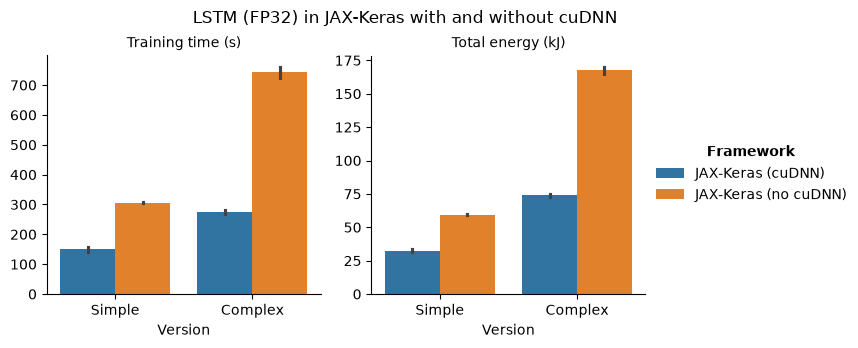

In [109]:
plot_df = cudnn_metrics_df.melt(
    id_vars=experiment_config,
    value_vars=["training_time", "train_cc_energy"],
    var_name="measure",
    value_name="value"
)
plot_df["backend_label"] = plot_df["backend"].map(cudnn_labels)
plot_df["model_complexity"] = plot_df["model_complexity"].map(labels["model_complexity"])
plot_df["measure"] = plot_df["measure"].map({
    "training_time": "Training time (s)",
    "train_cc_energy": "Total energy (kJ)",
})

plot = sns.catplot(
    data=plot_df,
    x="model_complexity",
    y="value",
    hue="backend_label",
    hue_order=list(cudnn_labels.values()),
    col="measure",
    kind="bar",
    errorbar=t_ci,
    order=list(labels["model_complexity"].values()),
    sharey=False,
    height=3.5
)

plot.set_titles(col_template="{col_name}")
plot.set_axis_labels(titles["model_complexity"], "")
plot._legend.set_title(r"$\bf{Framework}$")
add_title(plot, "LSTM (FP32) in JAX-Keras with and without cuDNN", adjust=0.85)

save_plot(plot, "LSTM/cudnn_comparison_LSTM")